# 03 — EDA & Trực quan hóa dữ liệu

**Bài tập 3 — Tuần 8 | BQ01: Dự đoán giá rao bán BĐS tại TP.HCM**

Notebook này nối trực tiếp từ production processed của Bài tập 2. Mục tiêu: phân tích missing/outlier, tạo ≥8 biểu đồ, rút ra 5–7 insight và chuẩn bị feature engineering cho Bài tập 4.

**Nguyên tắc:** raw không sửa; không dùng `price_per_m2` làm feature khi target là `price_vnd`; mọi con số trong notebook được tính lại từ production hiện tại.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, HTML, Markdown

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from dap_project.pipelines.eda import run_eda, find_latest_processed

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
print('Project root:', PROJECT_ROOT)

Project root: C:\Users\LEGION\Downloads\DAP_Final_Project_BT1_BT2\DAP_Final_Project


## 1. Nguồn dữ liệu và profiling ban đầu

In [2]:
source = find_latest_processed(PROJECT_ROOT)
df = pd.read_csv(source)
print('Source:', source)
print('Shape:', df.shape)
display(df.head(3))
display(df[['price_vnd', 'area_m2']].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T)

Source: C:\Users\LEGION\Downloads\DAP_Final_Project_BT1_BT2\DAP_Final_Project\data\processed\hcm_realestate_20260912_163121.csv
Shape: (6452, 22)


,source,url,title,price_text,area_text,location_text,update_text,property_type,crawl_page,crawled_at,listing_id,description,listing_date,price_vnd,area_m2,scope_status,current_ward,legacy_area,price_valid,area_valid,area_definition_risk,estimated_land_area_from_title
0,cafeland,https://nhadat.cafeland.vn/can-ban-can-ho-coni...,Cần bán căn hộ Conic Boulevard Bình Chánh ngay...,2 tỷ 850 triệu,85m2,Cần bán căn hộ Conic Boulevard Bình Chánh ngay...,Hôm nay 0906 114***,apartment,1,2026-09-12T16:50:28,3179952,NaN,NaN,"2,850,000,000.00",85.00,confirmed_by_current_ward,Bình Chánh,Huyện Bình Chánh,True,True,False,NaN
1,cafeland,https://nhadat.cafeland.vn/moi-gioi/kieu-phuon...,Kiều Phương Thảo,2 tỷ 850 triệu,85m2,Cần bán căn hộ Conic Boulevard Bình Chánh ngay...,Hôm nay 0906 114***,unknown,1,2026-09-12T16:50:28,247306,NaN,NaN,"2,850,000,000.00",85.00,confirmed_by_current_ward,Bình Chánh,Huyện Bình Chánh,True,True,False,NaN
2,cafeland,https://nhadat.cafeland.vn/ban-nha-moi-keng-ma...,"BÁN NHÀ MỚI KENG MẶT TIỀN TÂN XUÂN, HÓC MÔN ,S...","5,35 TỶ",100m2,"BÁN NHÀ MỚI KENG MẶT TIỀN TÂN XUÂN, HÓC MÔN ,S...",Hôm nay 0977 830***,house,1,2026-09-12T16:50:28,2485915,NaN,NaN,"5,350,000,000.00",100.00,confirmed_by_current_ward,Hóc Môn,Huyện Hóc Môn,True,True,False,NaN


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
price_vnd,"6,452.00","27,948,027,464.35","66,064,813,926.25","2,500,000.00","200,000,000.00","1,317,750,000.00","5,100,000,000.00","9,200,000,000.00","25,000,000,000.00","100,000,000,000.00","350,000,000,000.00","970,000,000,000.00"
area_m2,"6,452.00",636.92,"12,231.90",1.00,15.00,34.00,60.00,83.00,148.00,562.25,"3,468.23","700,000.00"


## 2. Chạy pipeline EDA có thể tái lập

In [3]:
result = run_eda(PROJECT_ROOT)
result['diagnostics']

{'input_rows': 6452,
 'structural_non_listing_rows': 304,
 'rows_after_structural_filter': 6148,
 'property_type_unknown_before': 1583,
 'property_type_refined_rows': 1001,
 'property_type_unknown_cleaned': 282,
 'outlier_price_log_rows': 32,
 'outlier_area_log_rows': 77,
 'outlier_price_per_m2_log_rows': 131,
 'robust_outlier_rows_removed': 62,
 'cleaned_rows': 6086,
 'retained_pct': 94.33,
 'area_definition_risk_rows_cleaned': 467}

## 3. Missing & outlier

Các trường thiếu cấu trúc như `description` và `listing_date` không được điền giả. Ngoại lai được đánh dấu trên log-scale theo `property_type`; chỉ loại khi một dòng nhận ít nhất 2/3 phiếu outlier robust.

In [4]:
missing = pd.read_csv(result['missing_policy_path'])
display(missing)
print('Cleaned rows:', result['diagnostics']['cleaned_rows'])
print('Robust outliers removed:', result['diagnostics']['robust_outlier_rows_removed'])
print('Property types refined:', result['diagnostics']['property_type_refined_rows'])

,column,missing_count,missing_rate_pct,mechanism,action
0,description,6086,100.00,Structural/MNAR-like,Card-only crawl does not expose description; d...
1,listing_date,6086,100.00,Structural/MNAR-like,Card-only crawl does not expose a reliable lis...
2,estimated_land_area_from_title,4166,68.45,MNAR-like,Available only when a title contains explicit ...
3,update_text,457,7.51,MAR/collection-layout,Keep missing as missing. Not used in model v1.
4,current_ward,358,5.88,MAR relative to scope mapping,Keep missing; legacy_area is used for district...
5,location_text,301,4.95,MAR/collection-layout,Use validated legacy_area for district-level EDA.


Cleaned rows: 6086
Robust outliers removed: 62
Property types refined: 1001


## 4. Cleaned dataset và feature availability

In [5]:
cleaned = pd.read_csv(result['cleaned_paths']['csv'])
availability = pd.read_csv(result['feature_availability_path'])
display(cleaned[['price_vnd','area_m2','property_type','legacy_area']].describe(include='all').T)
display(availability)
print('Model v1:', result['model_v1_features'])

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
price_vnd,"6,086.00",NaN,NaN,NaN,"27,959,814,968.78","65,260,361,036.15","10,000,000.00","5,300,000,000.00","9,500,000,000.00","25,000,000,000.00","942,000,000,000.00"
area_m2,"6,086.00",NaN,NaN,NaN,336.88,"4,505.63",1.00,60.00,83.00,146.00,"290,000.00"
property_type,6086,6,house,4089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
legacy_area,6086,22,TP Thủ Đức,1001,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,feature,present,non_null_rate,dtype
0,area_m2,True,1.00,float64
1,log_area_m2,True,1.00,float64
2,property_type,True,1.00,str
3,legacy_area,True,1.00,str
4,bedrooms,False,0.00,NaN
5,bathrooms,False,0.00,NaN
6,floors,False,0.00,NaN
7,road_width_m,False,0.00,NaN
8,legal_status,False,0.00,NaN
9,direction,False,0.00,NaN


Model v1: {'numeric': ['area_m2', 'log_area_m2'], 'categorical': ['property_type', 'legacy_area']}


## 5. Bộ biểu đồ EDA

### executive_dashboard

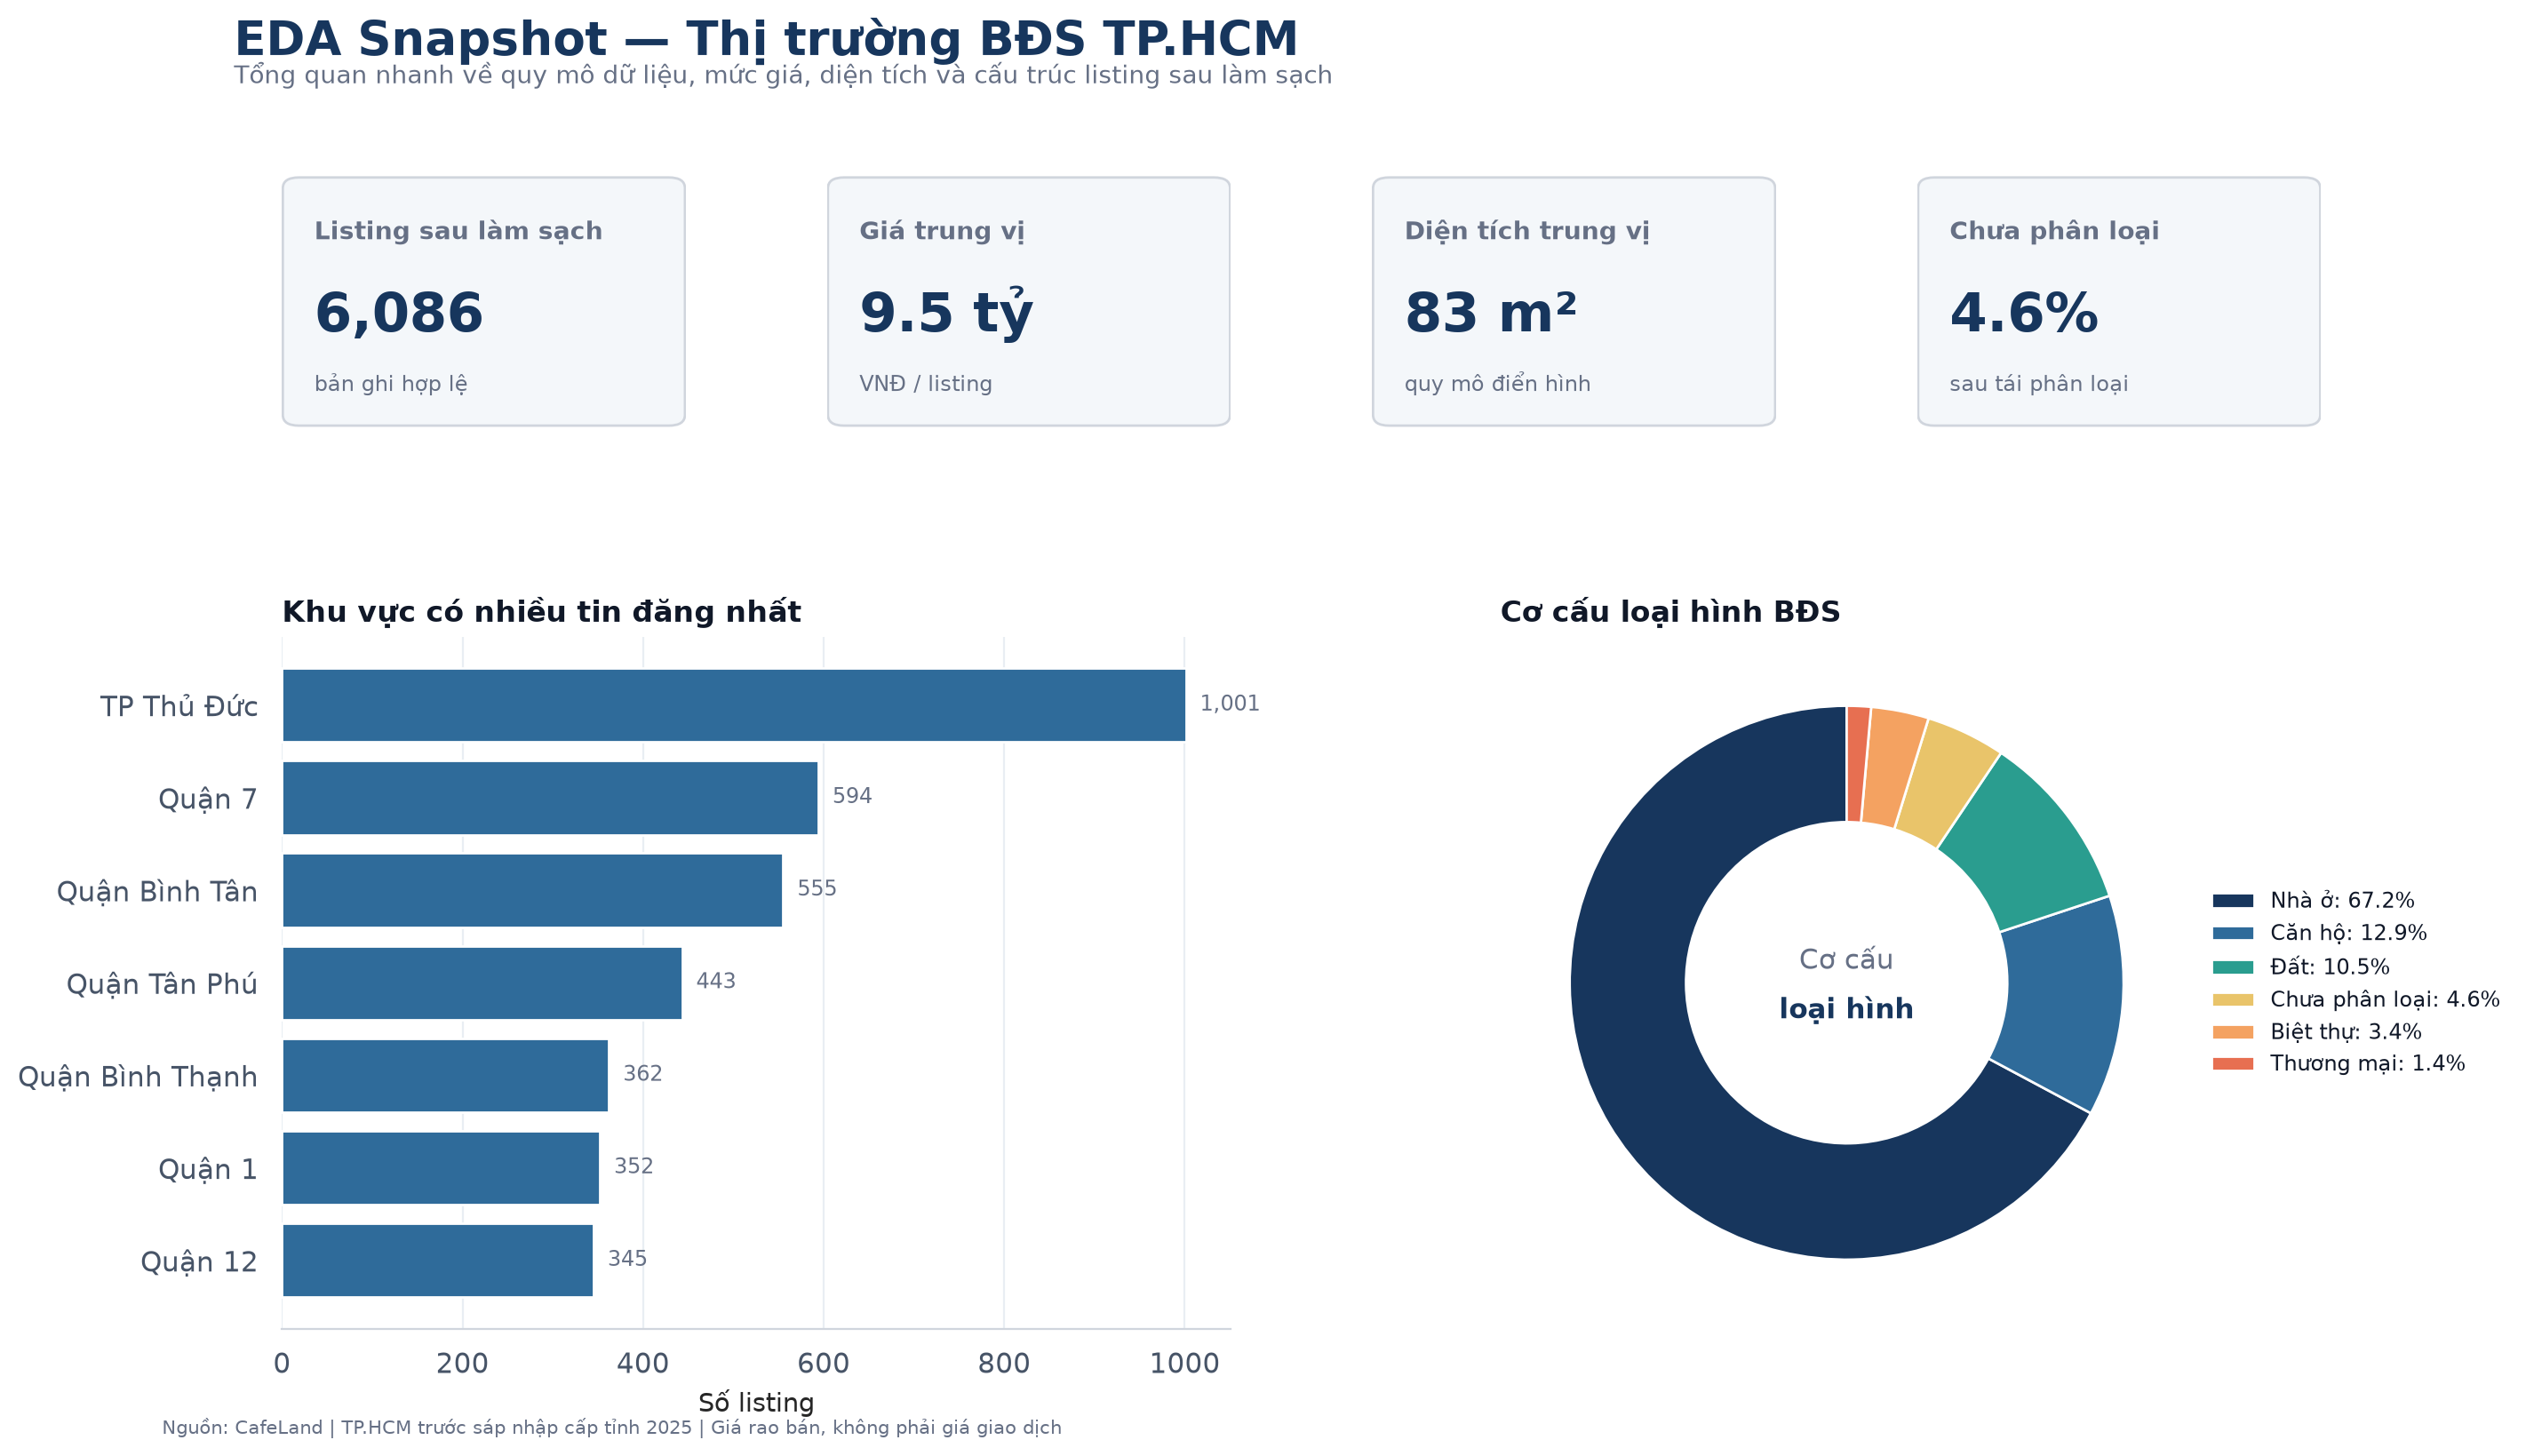

### price_distribution

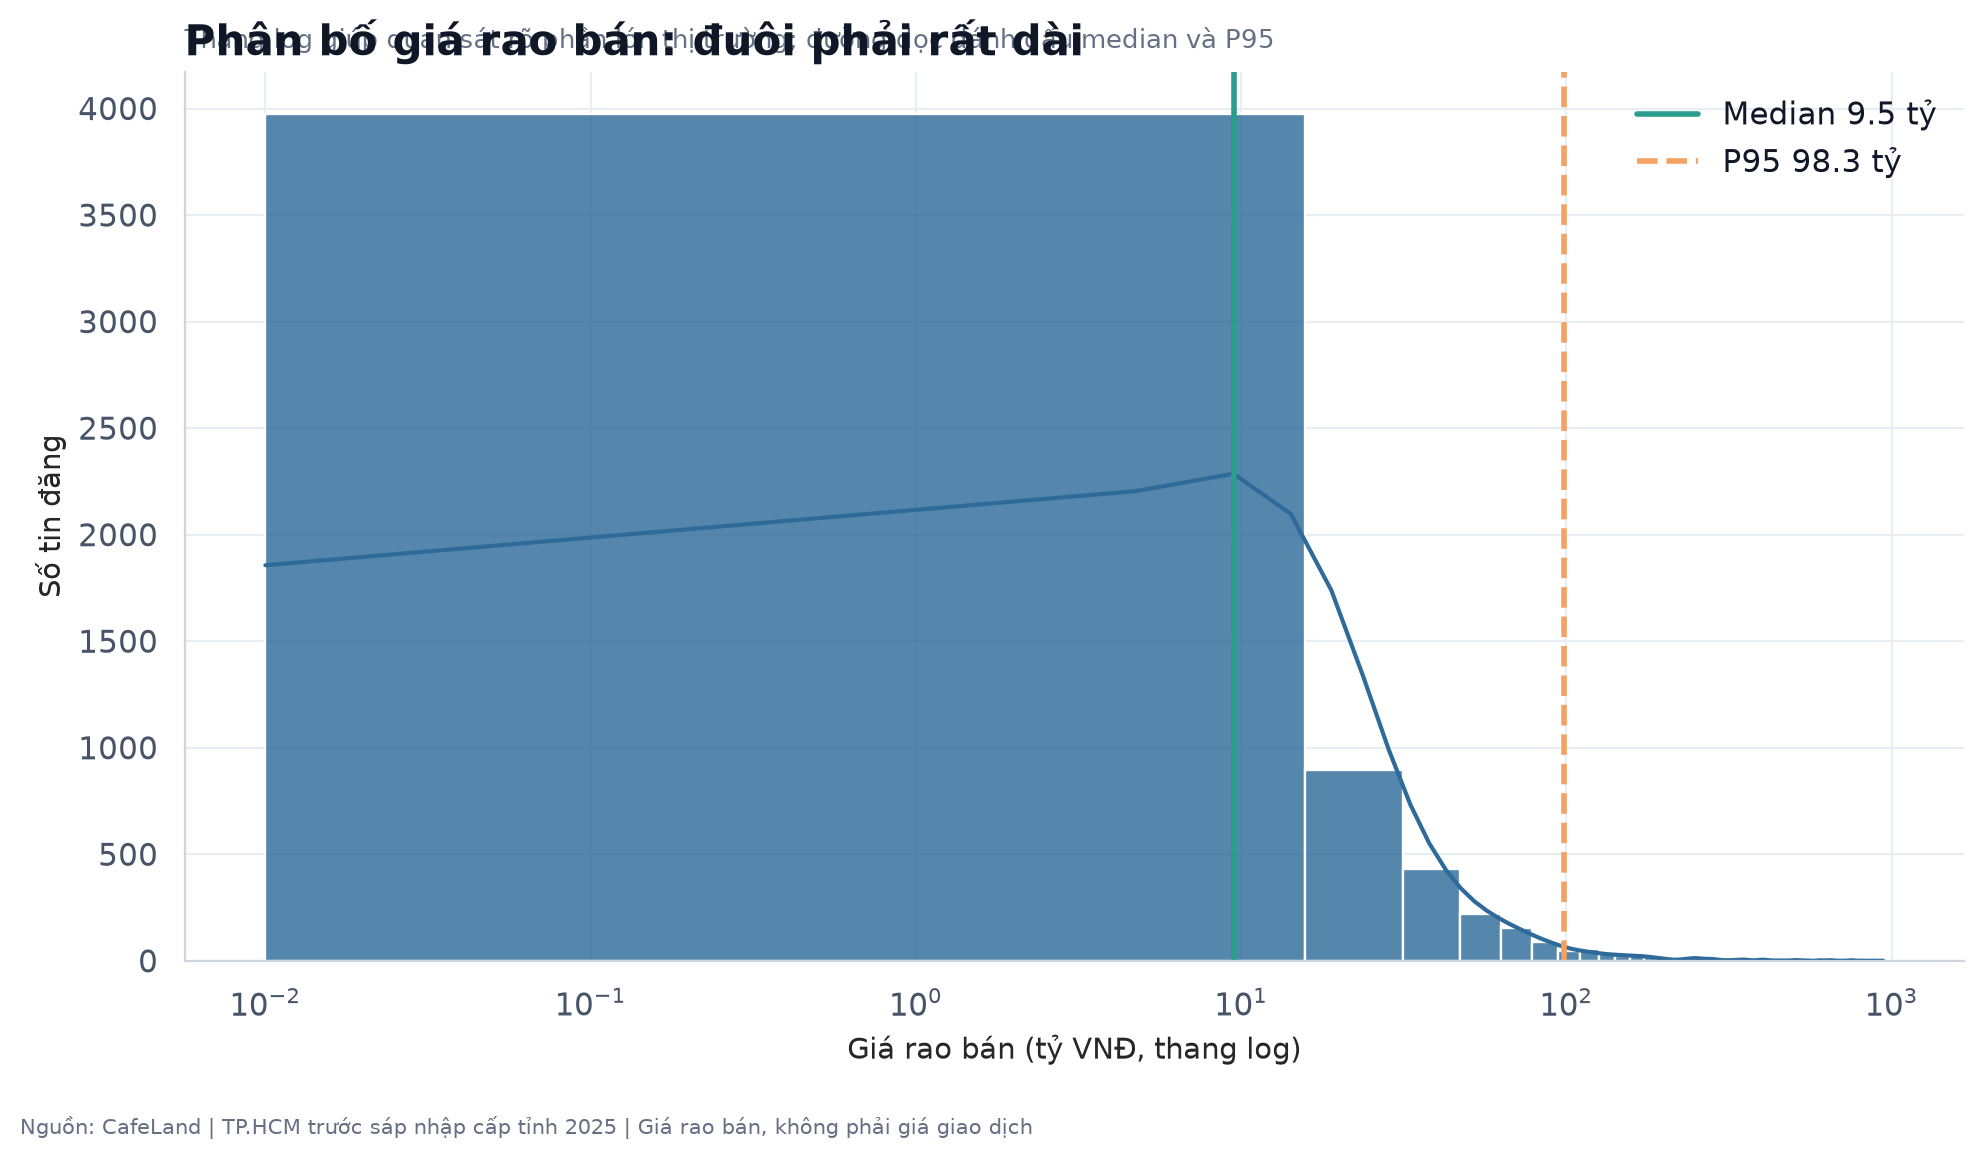

### area_distribution

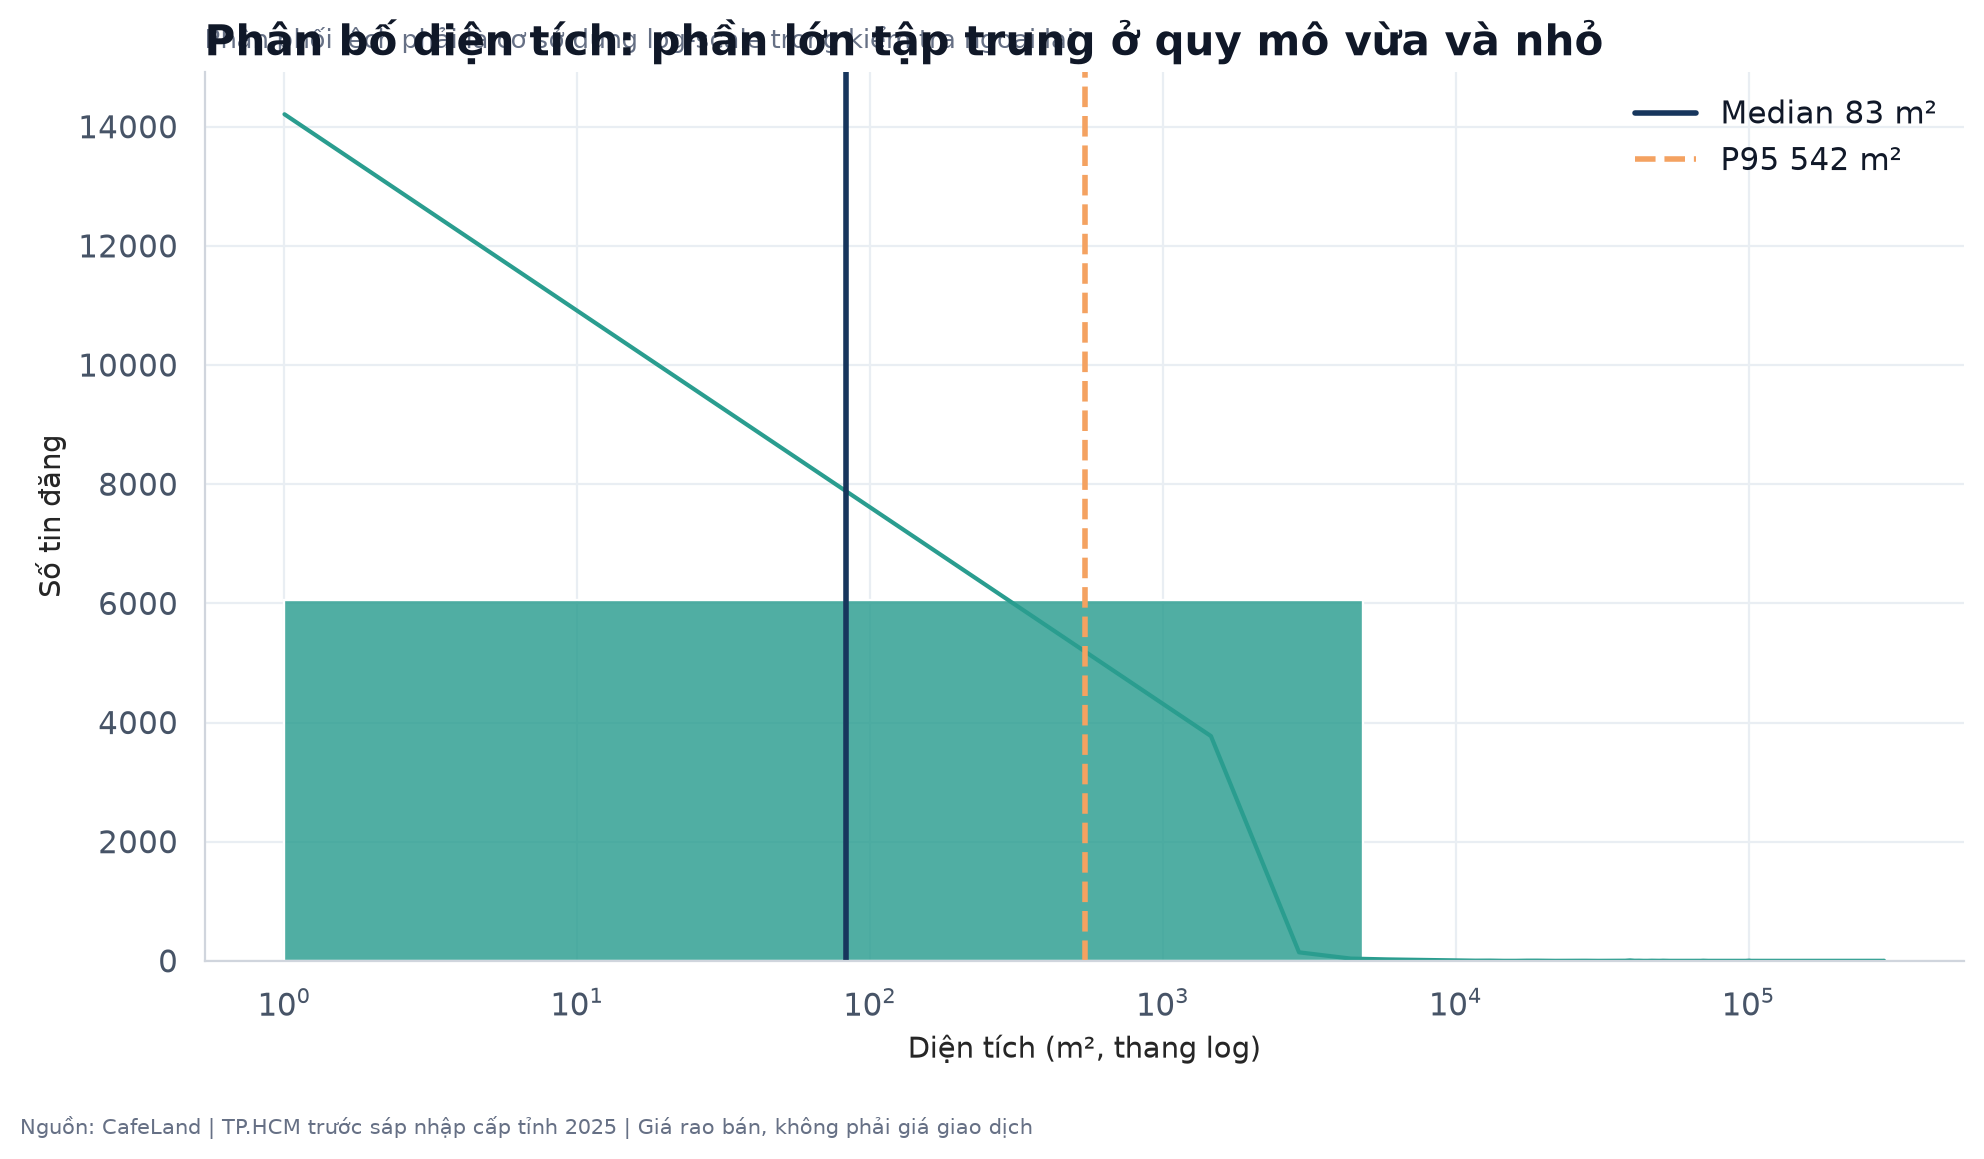

### property_type_distribution

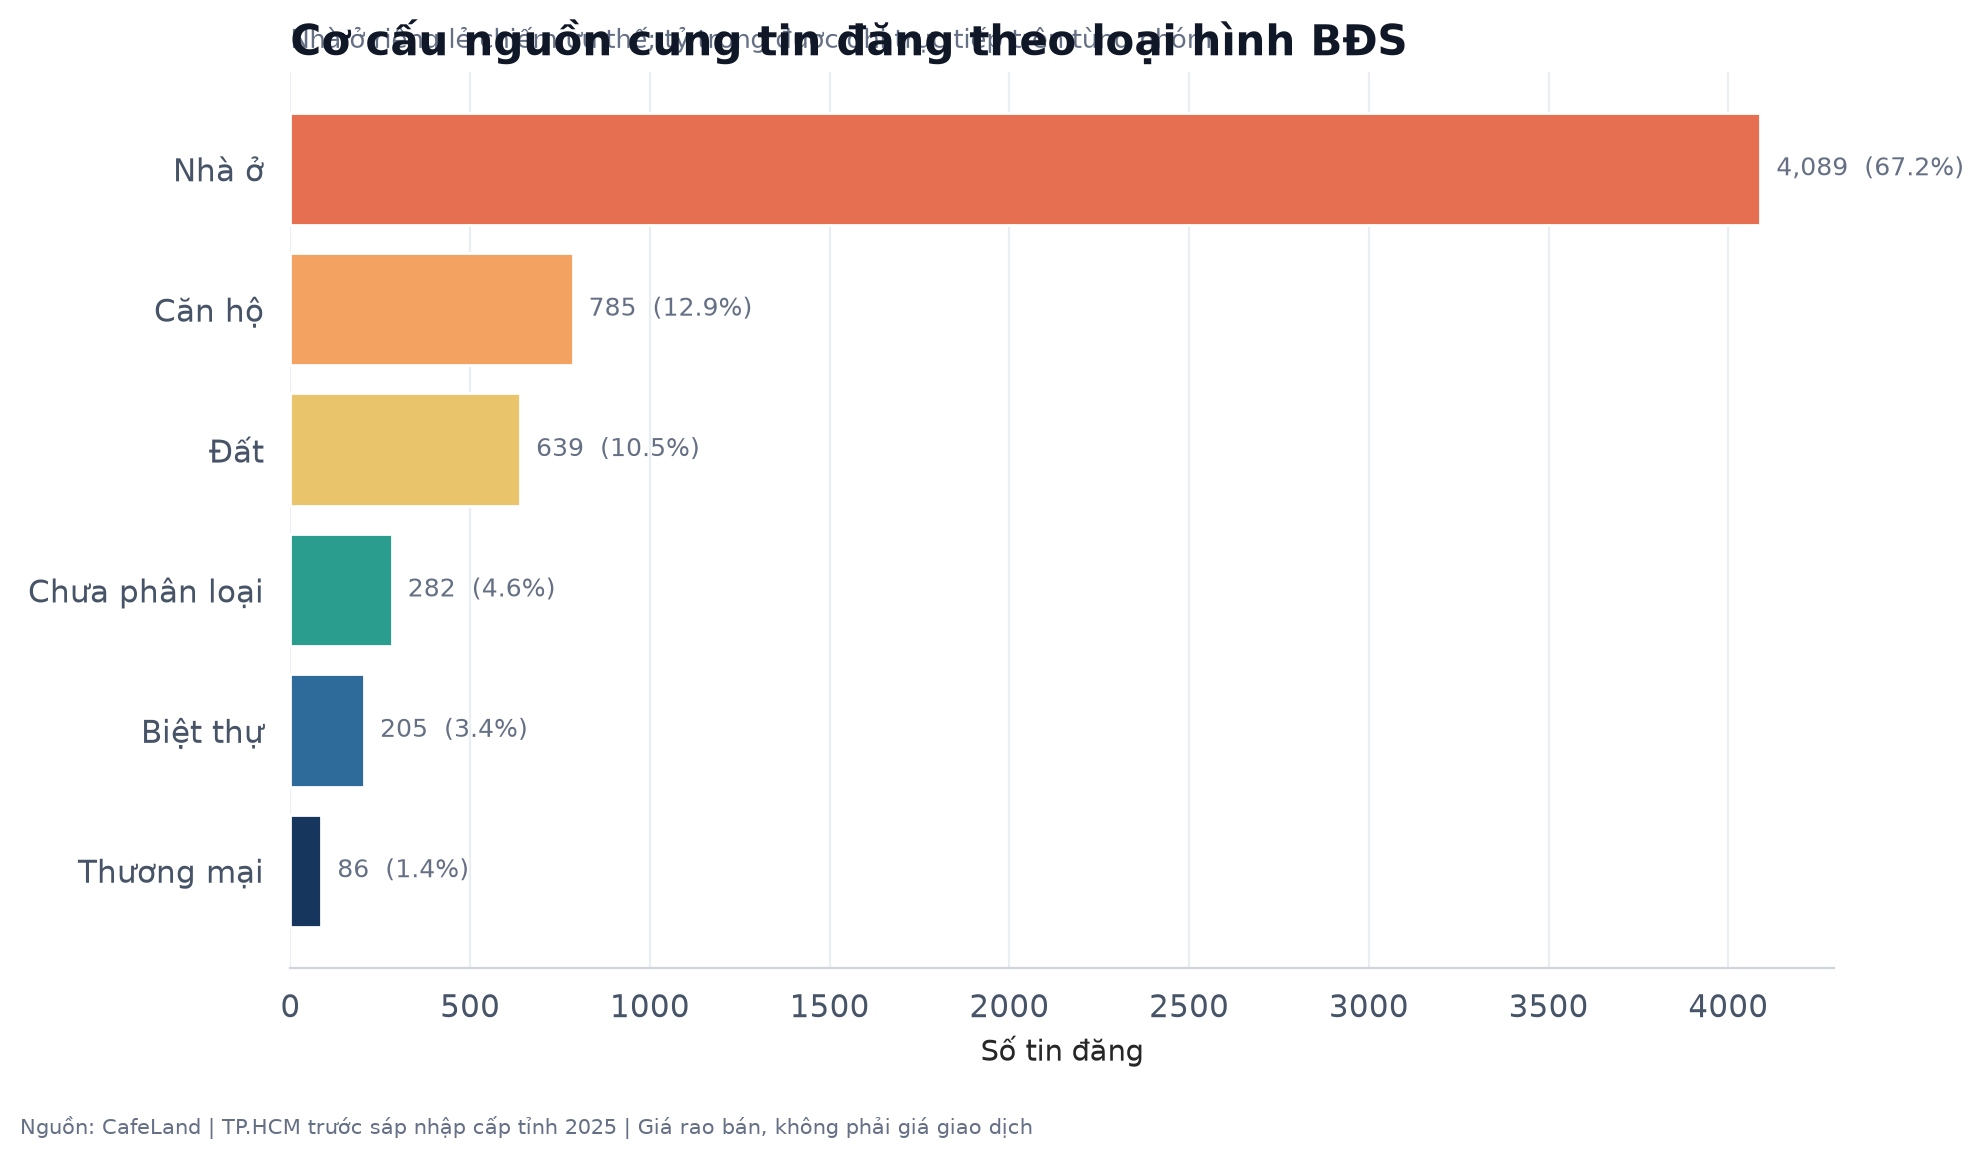

### price_m2_by_property_type

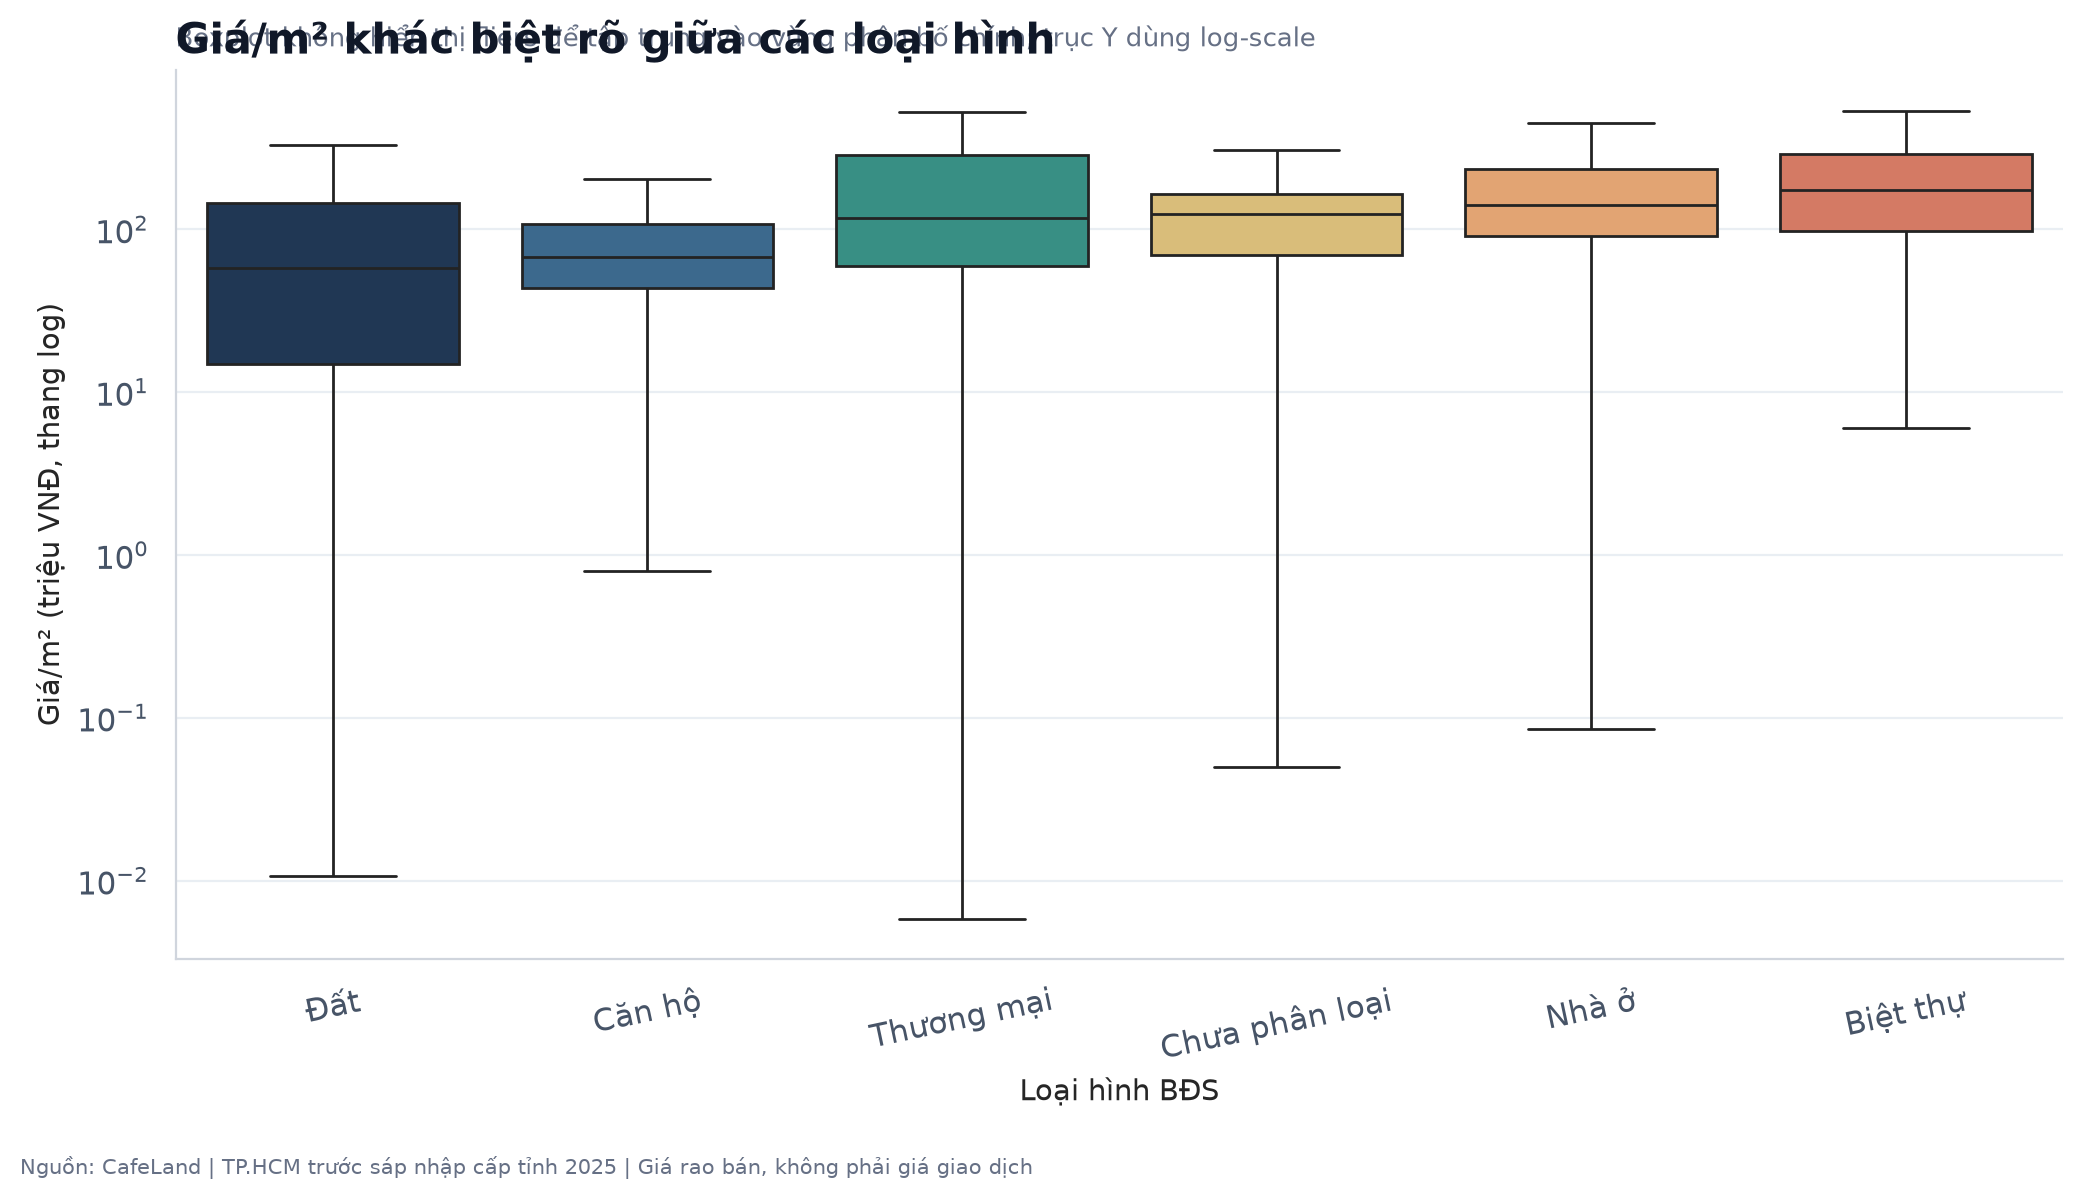

### price_m2_by_area

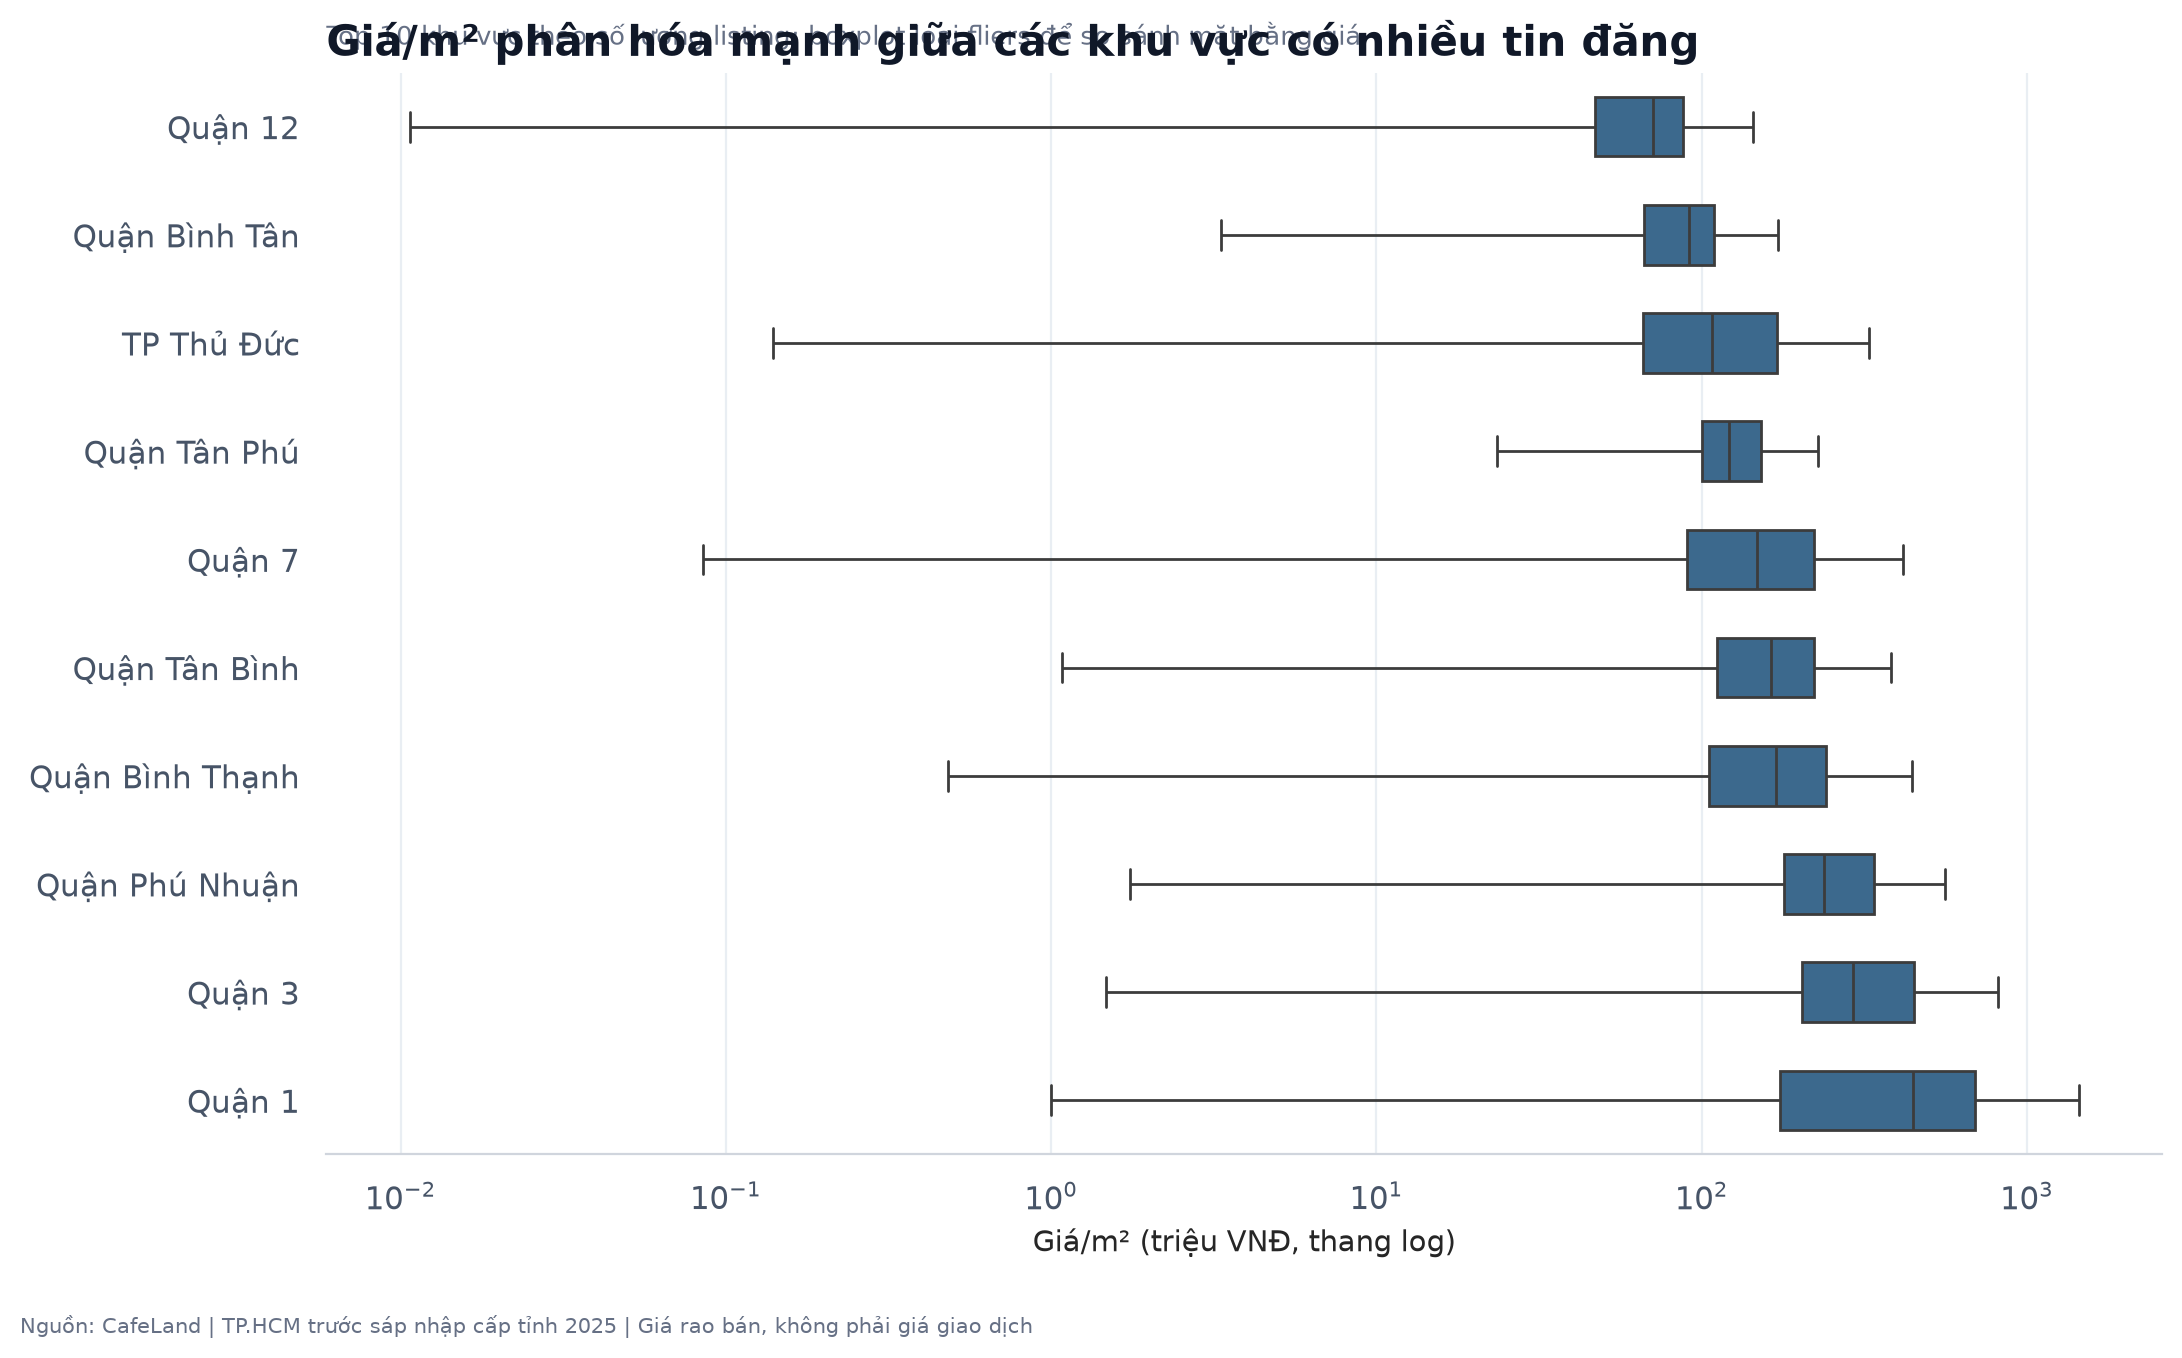

### price_vs_area

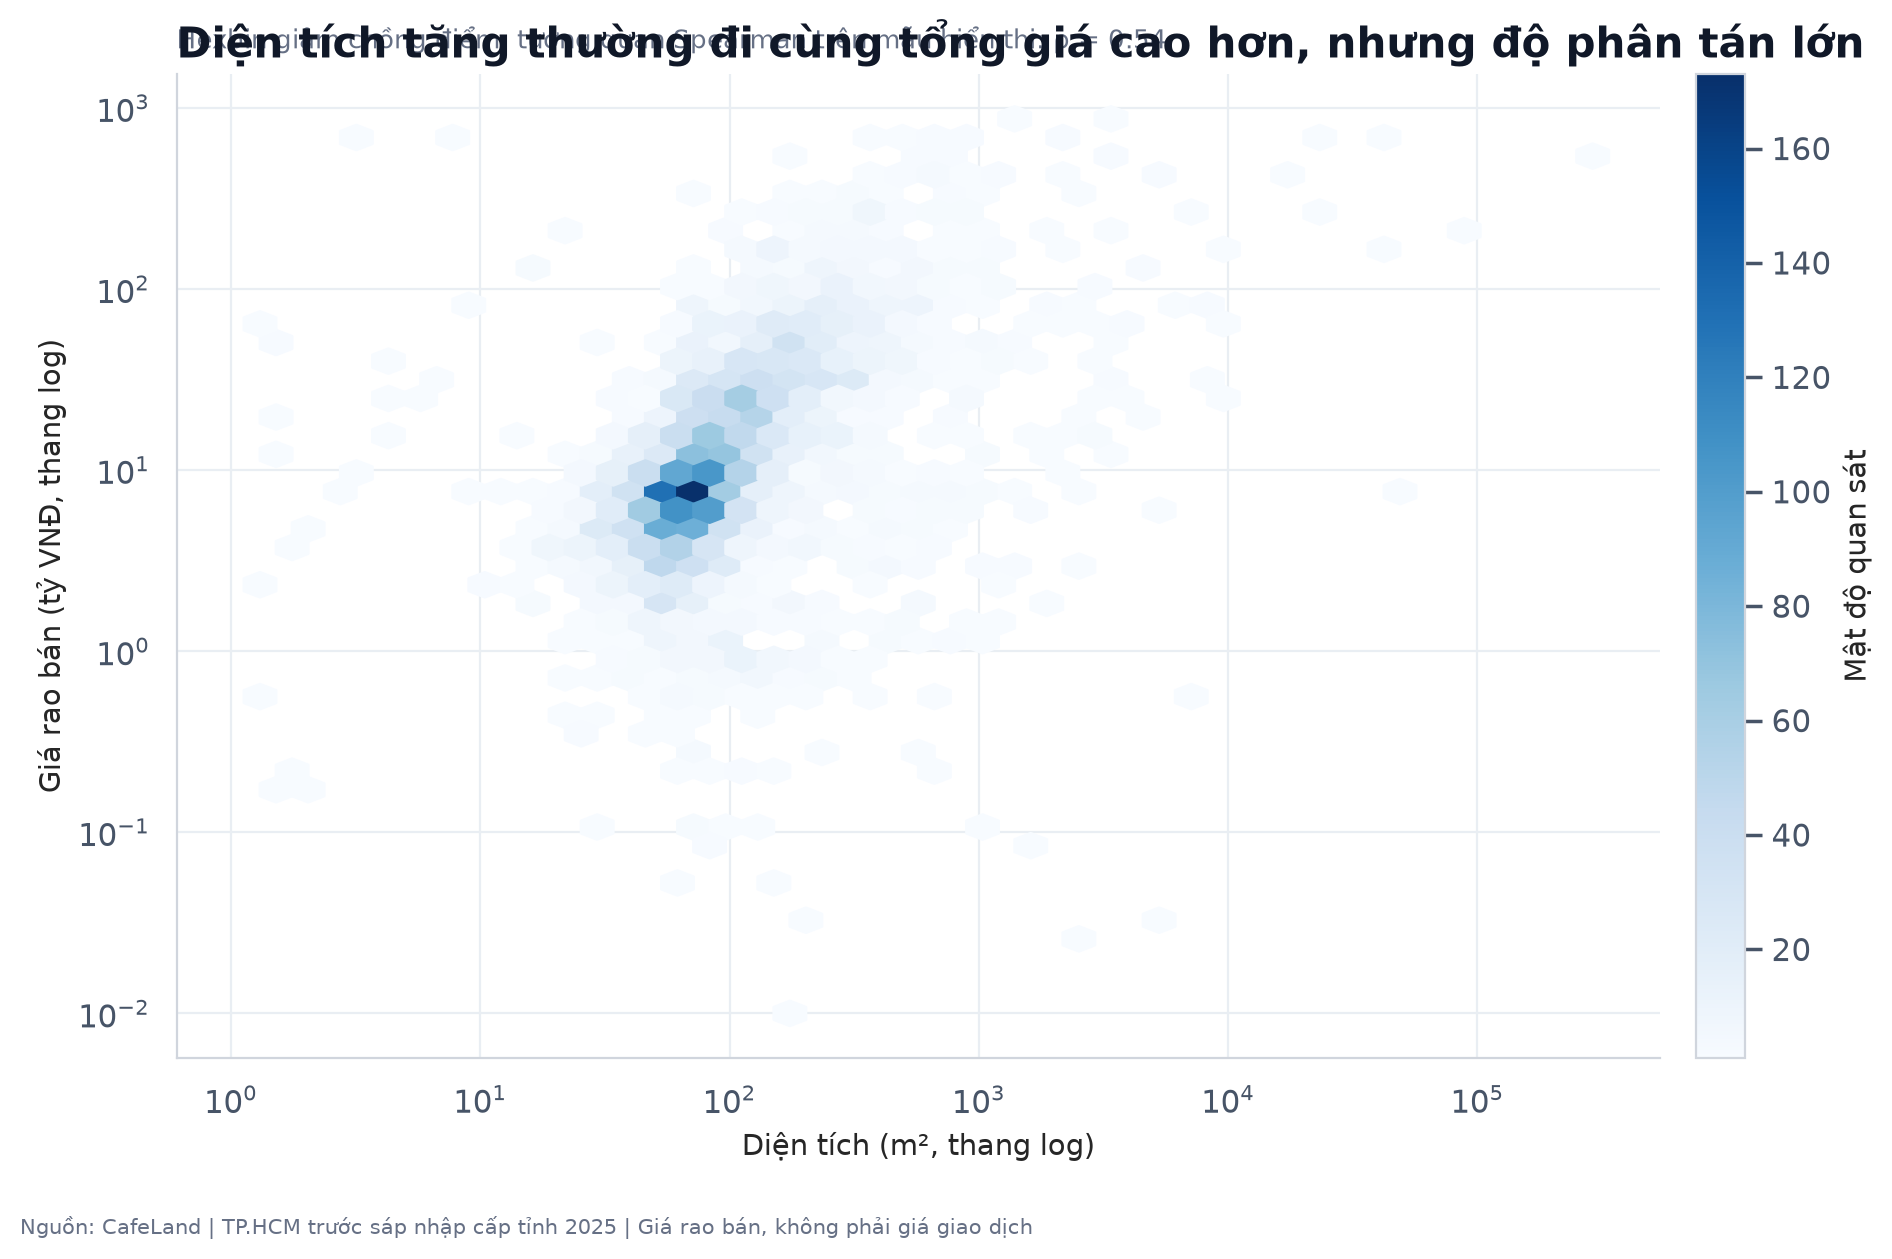

### listing_count_by_area

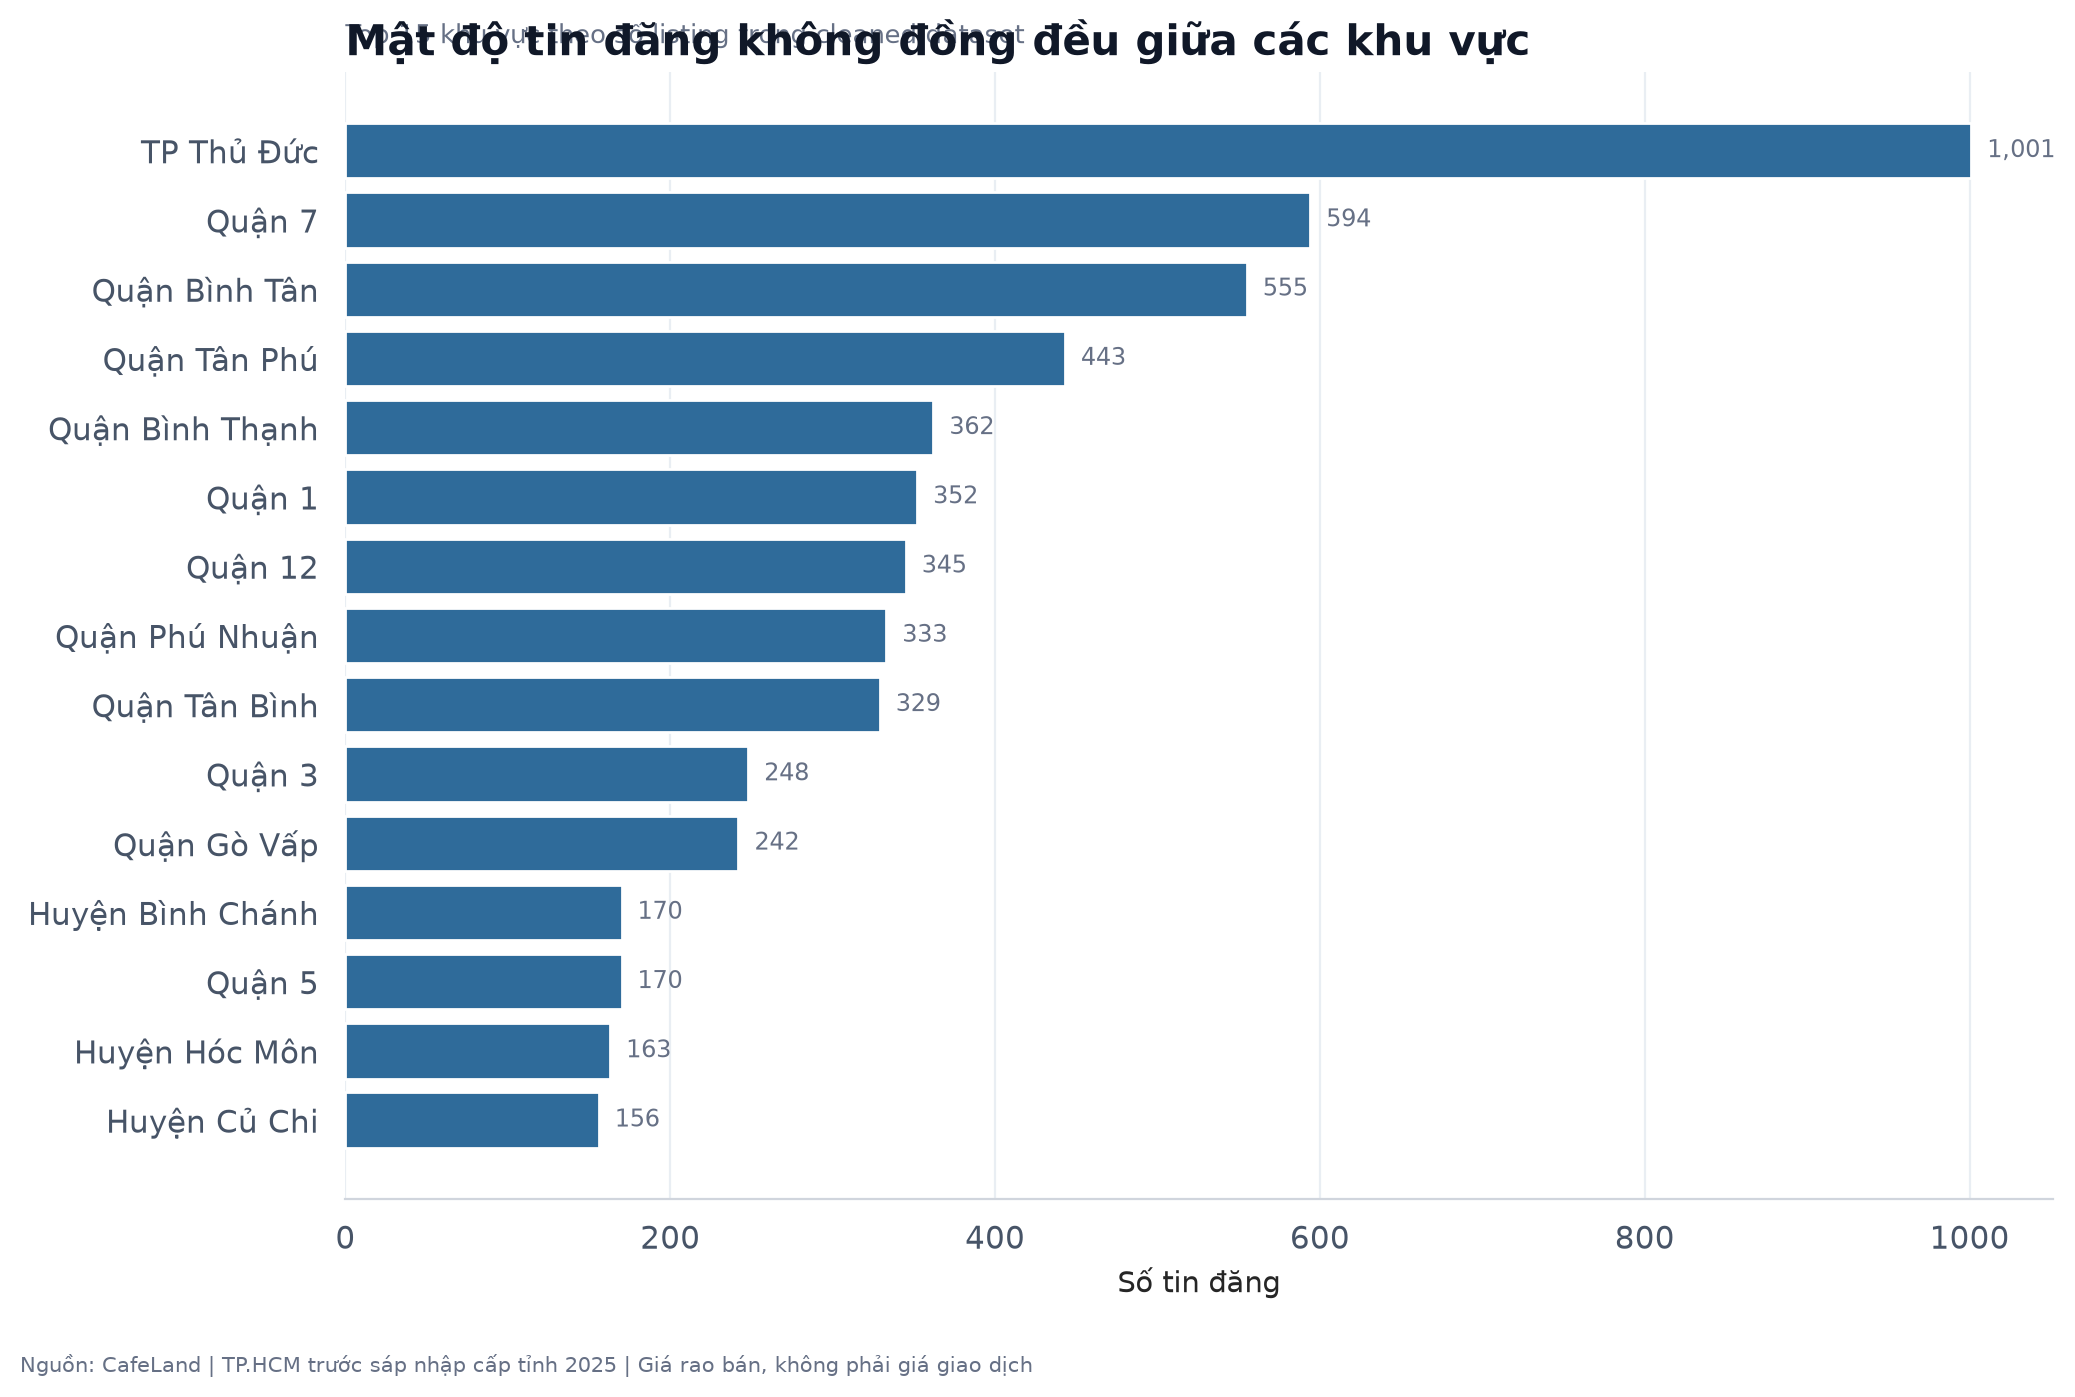

### median_price_m2_by_area

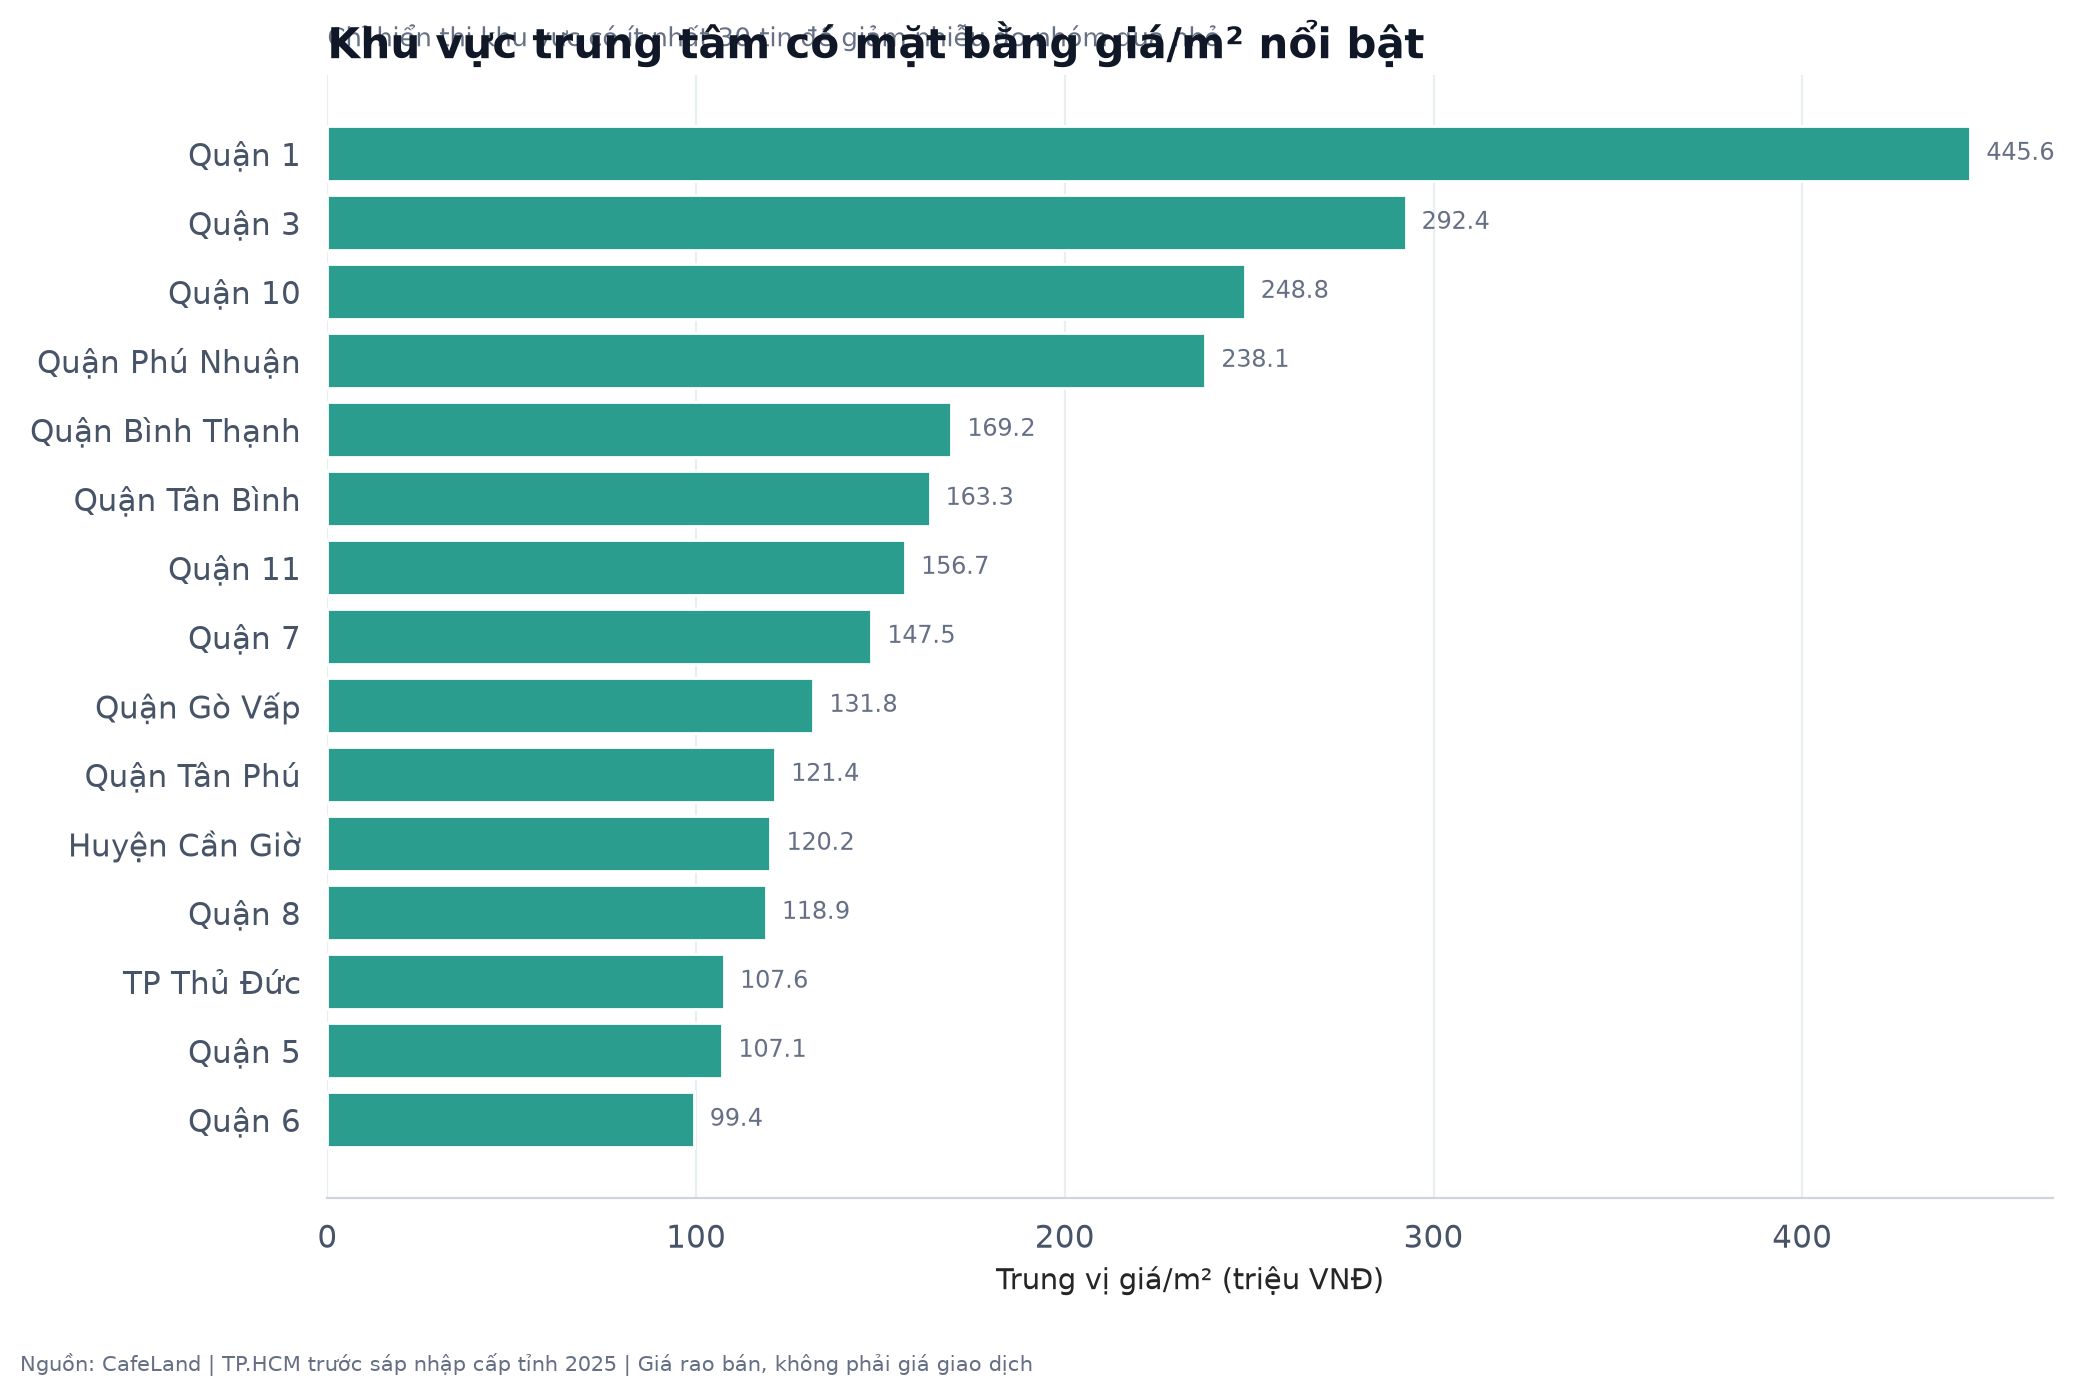

### correlation_heatmap

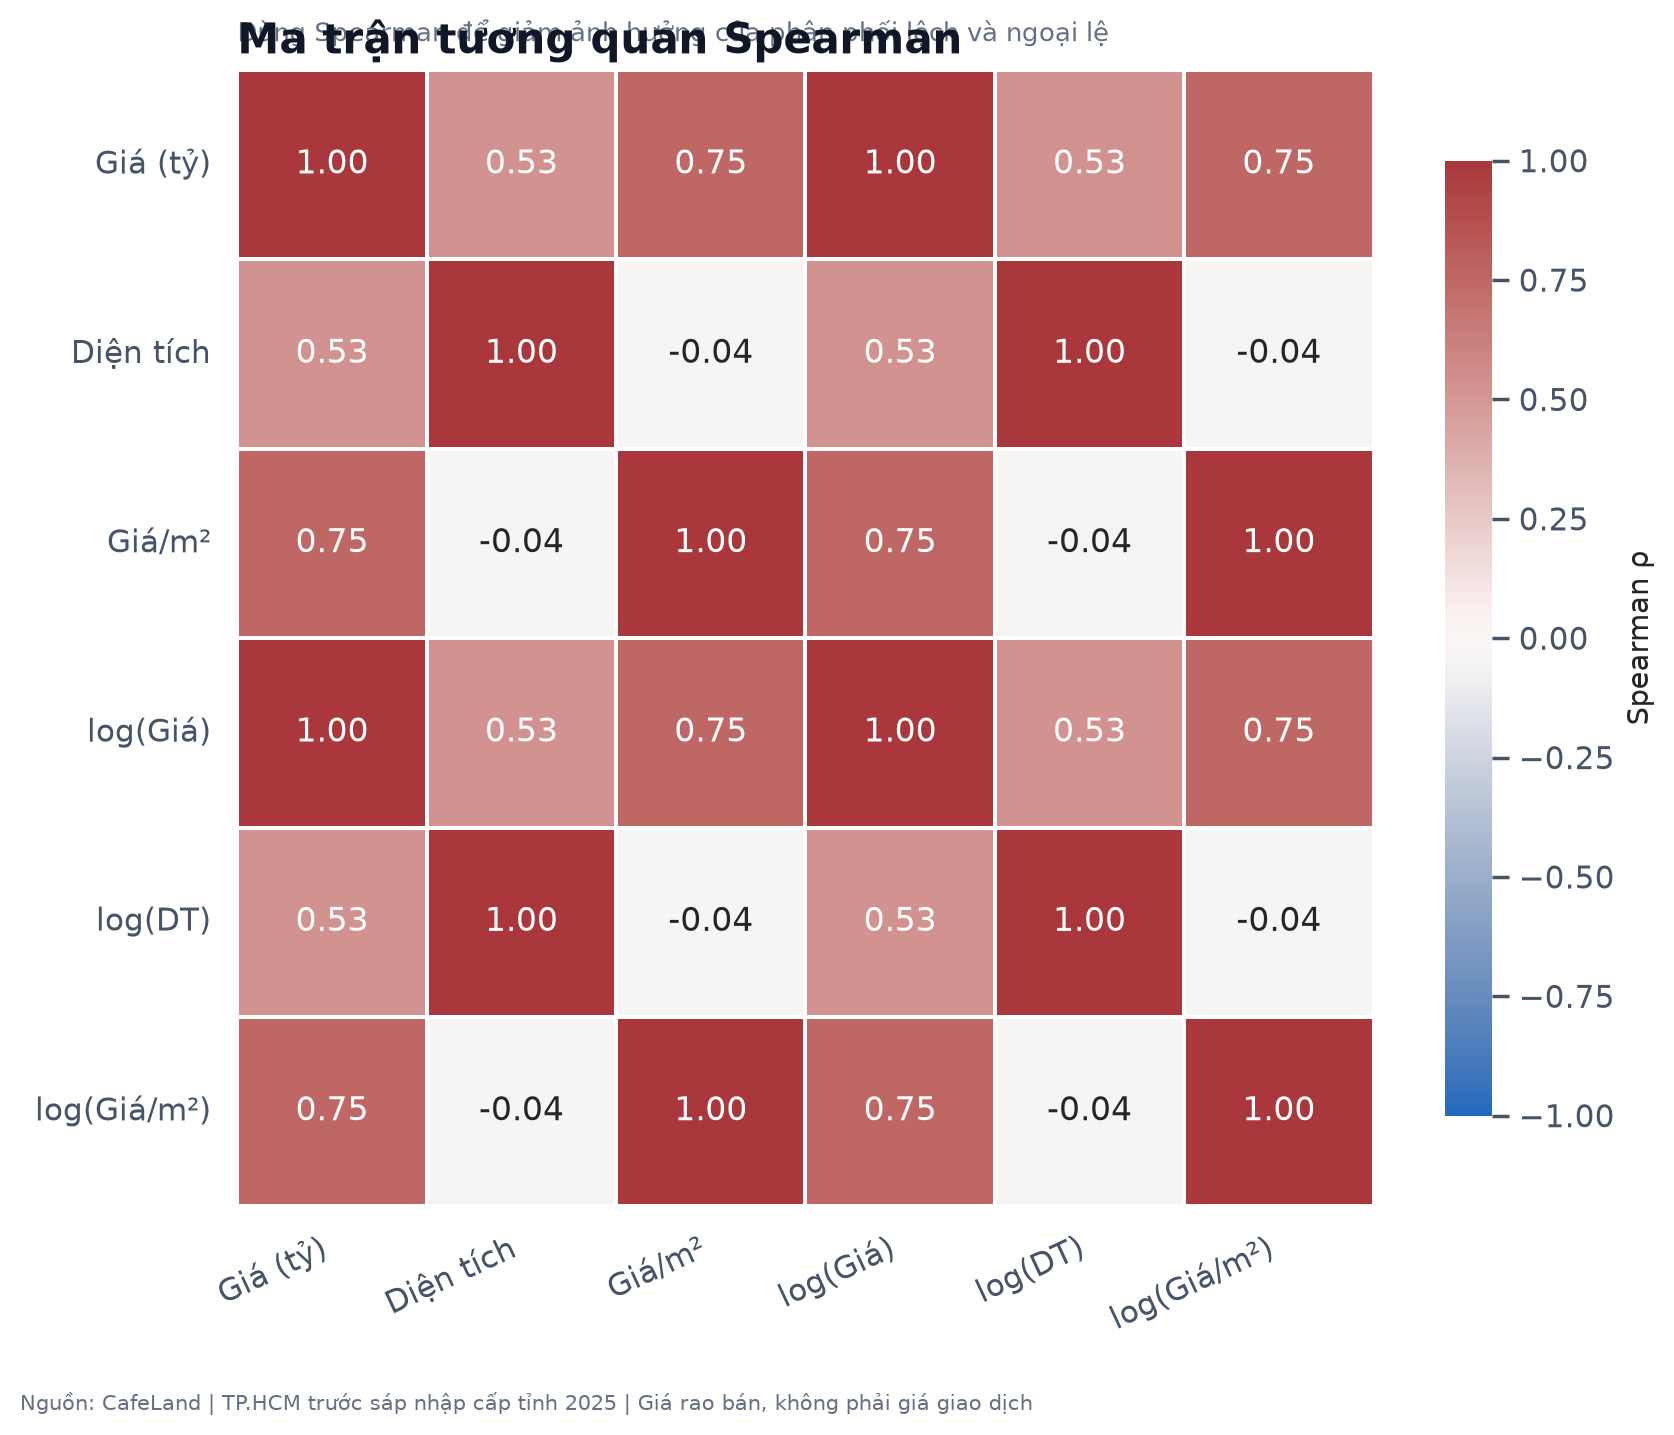

### cleaning_summary

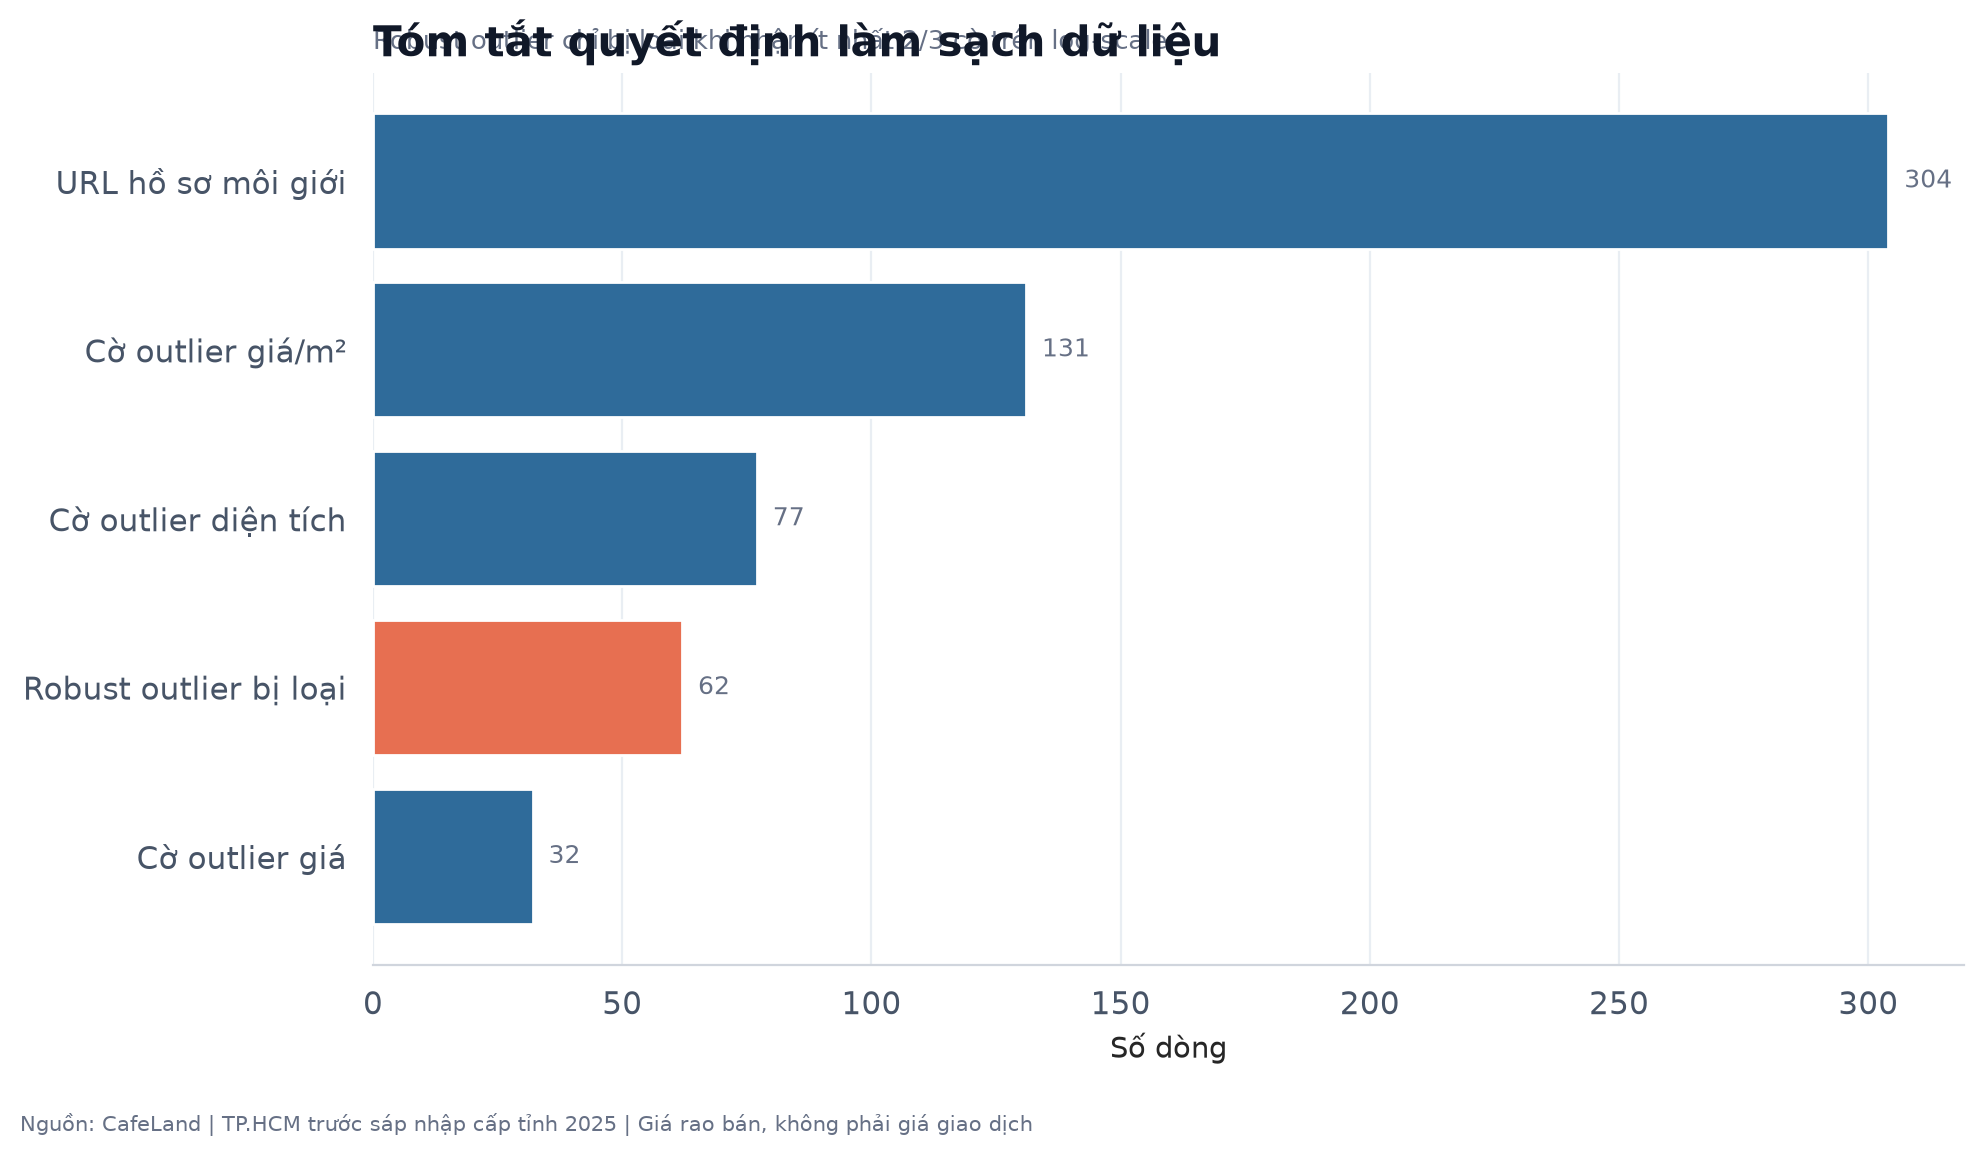

### missingness_profile

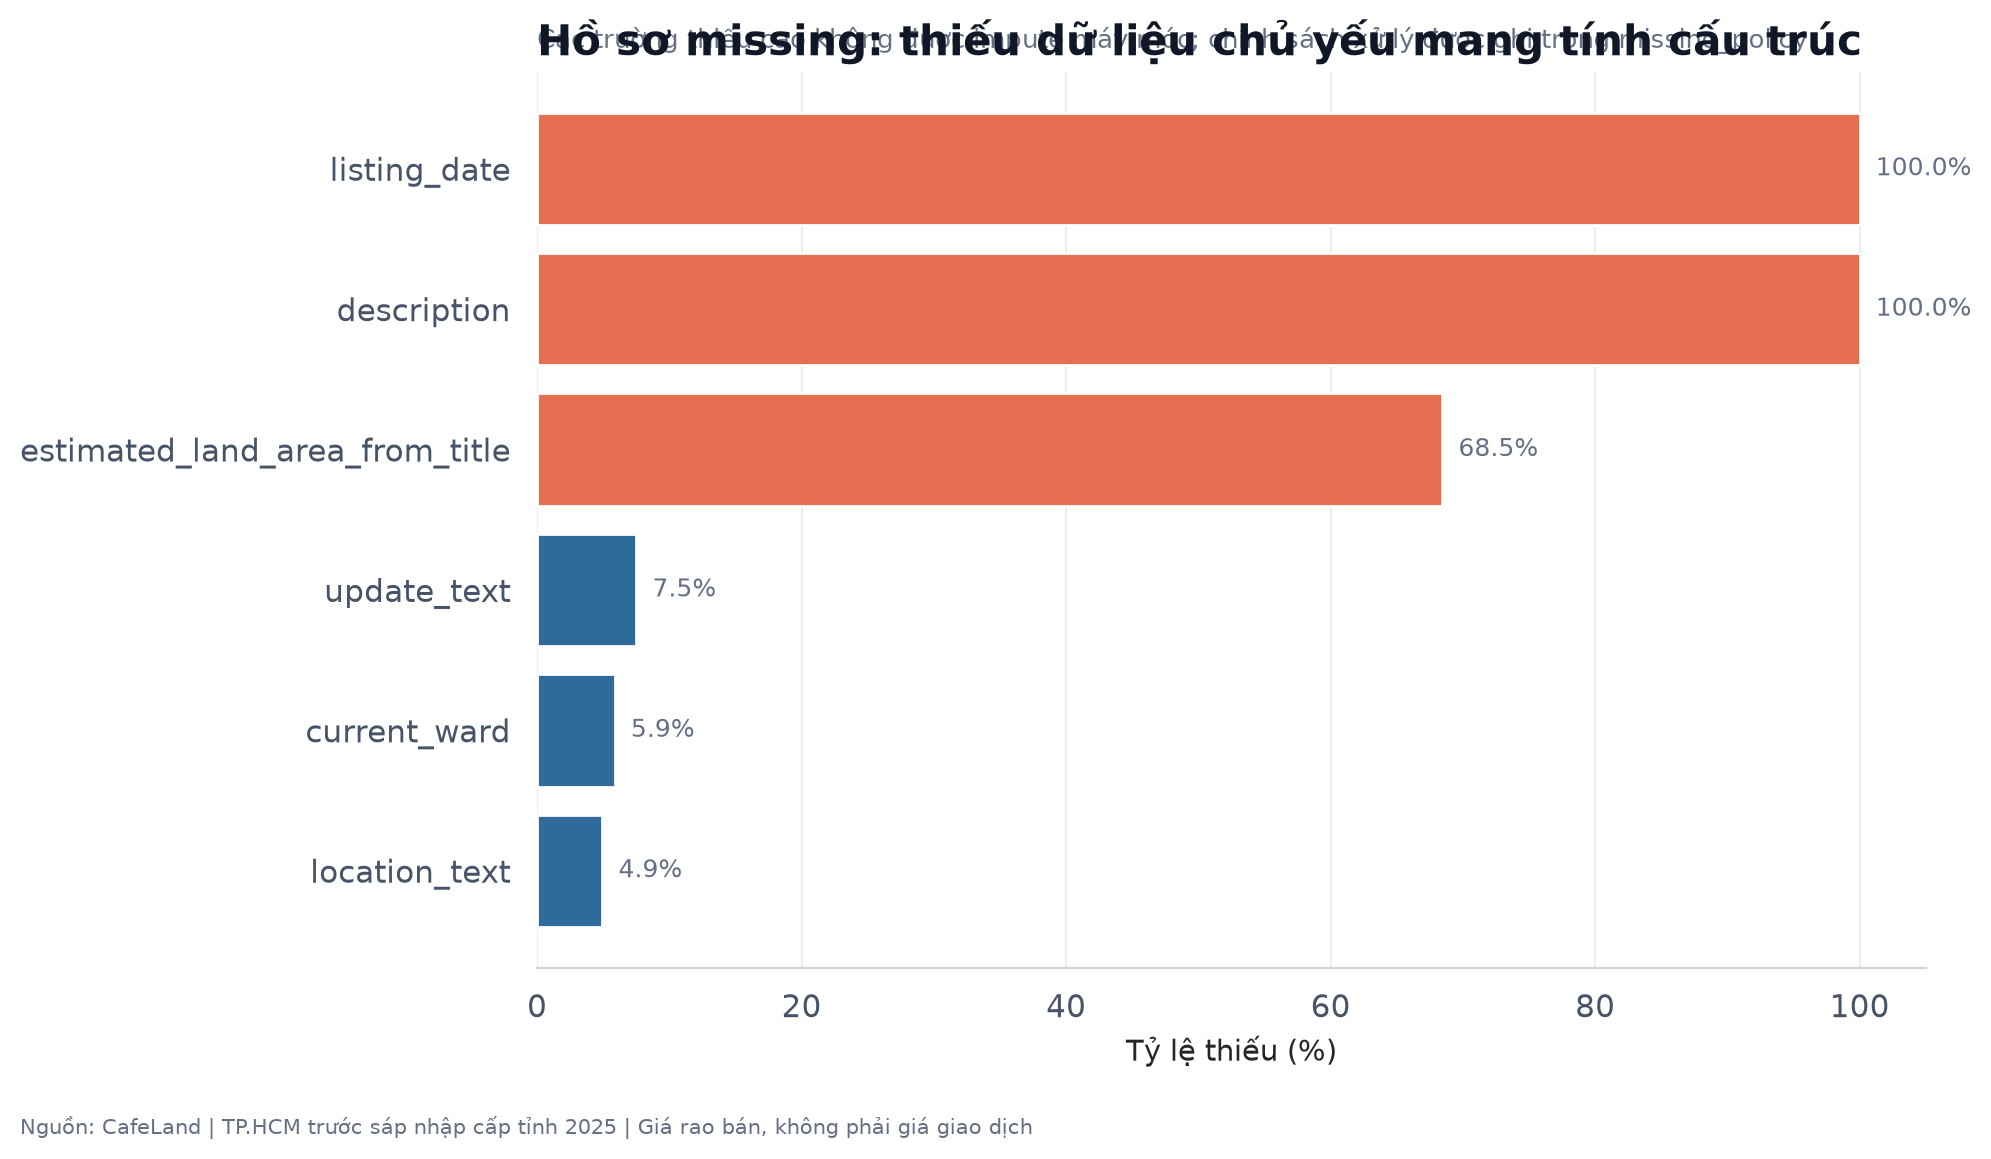

### market_positioning

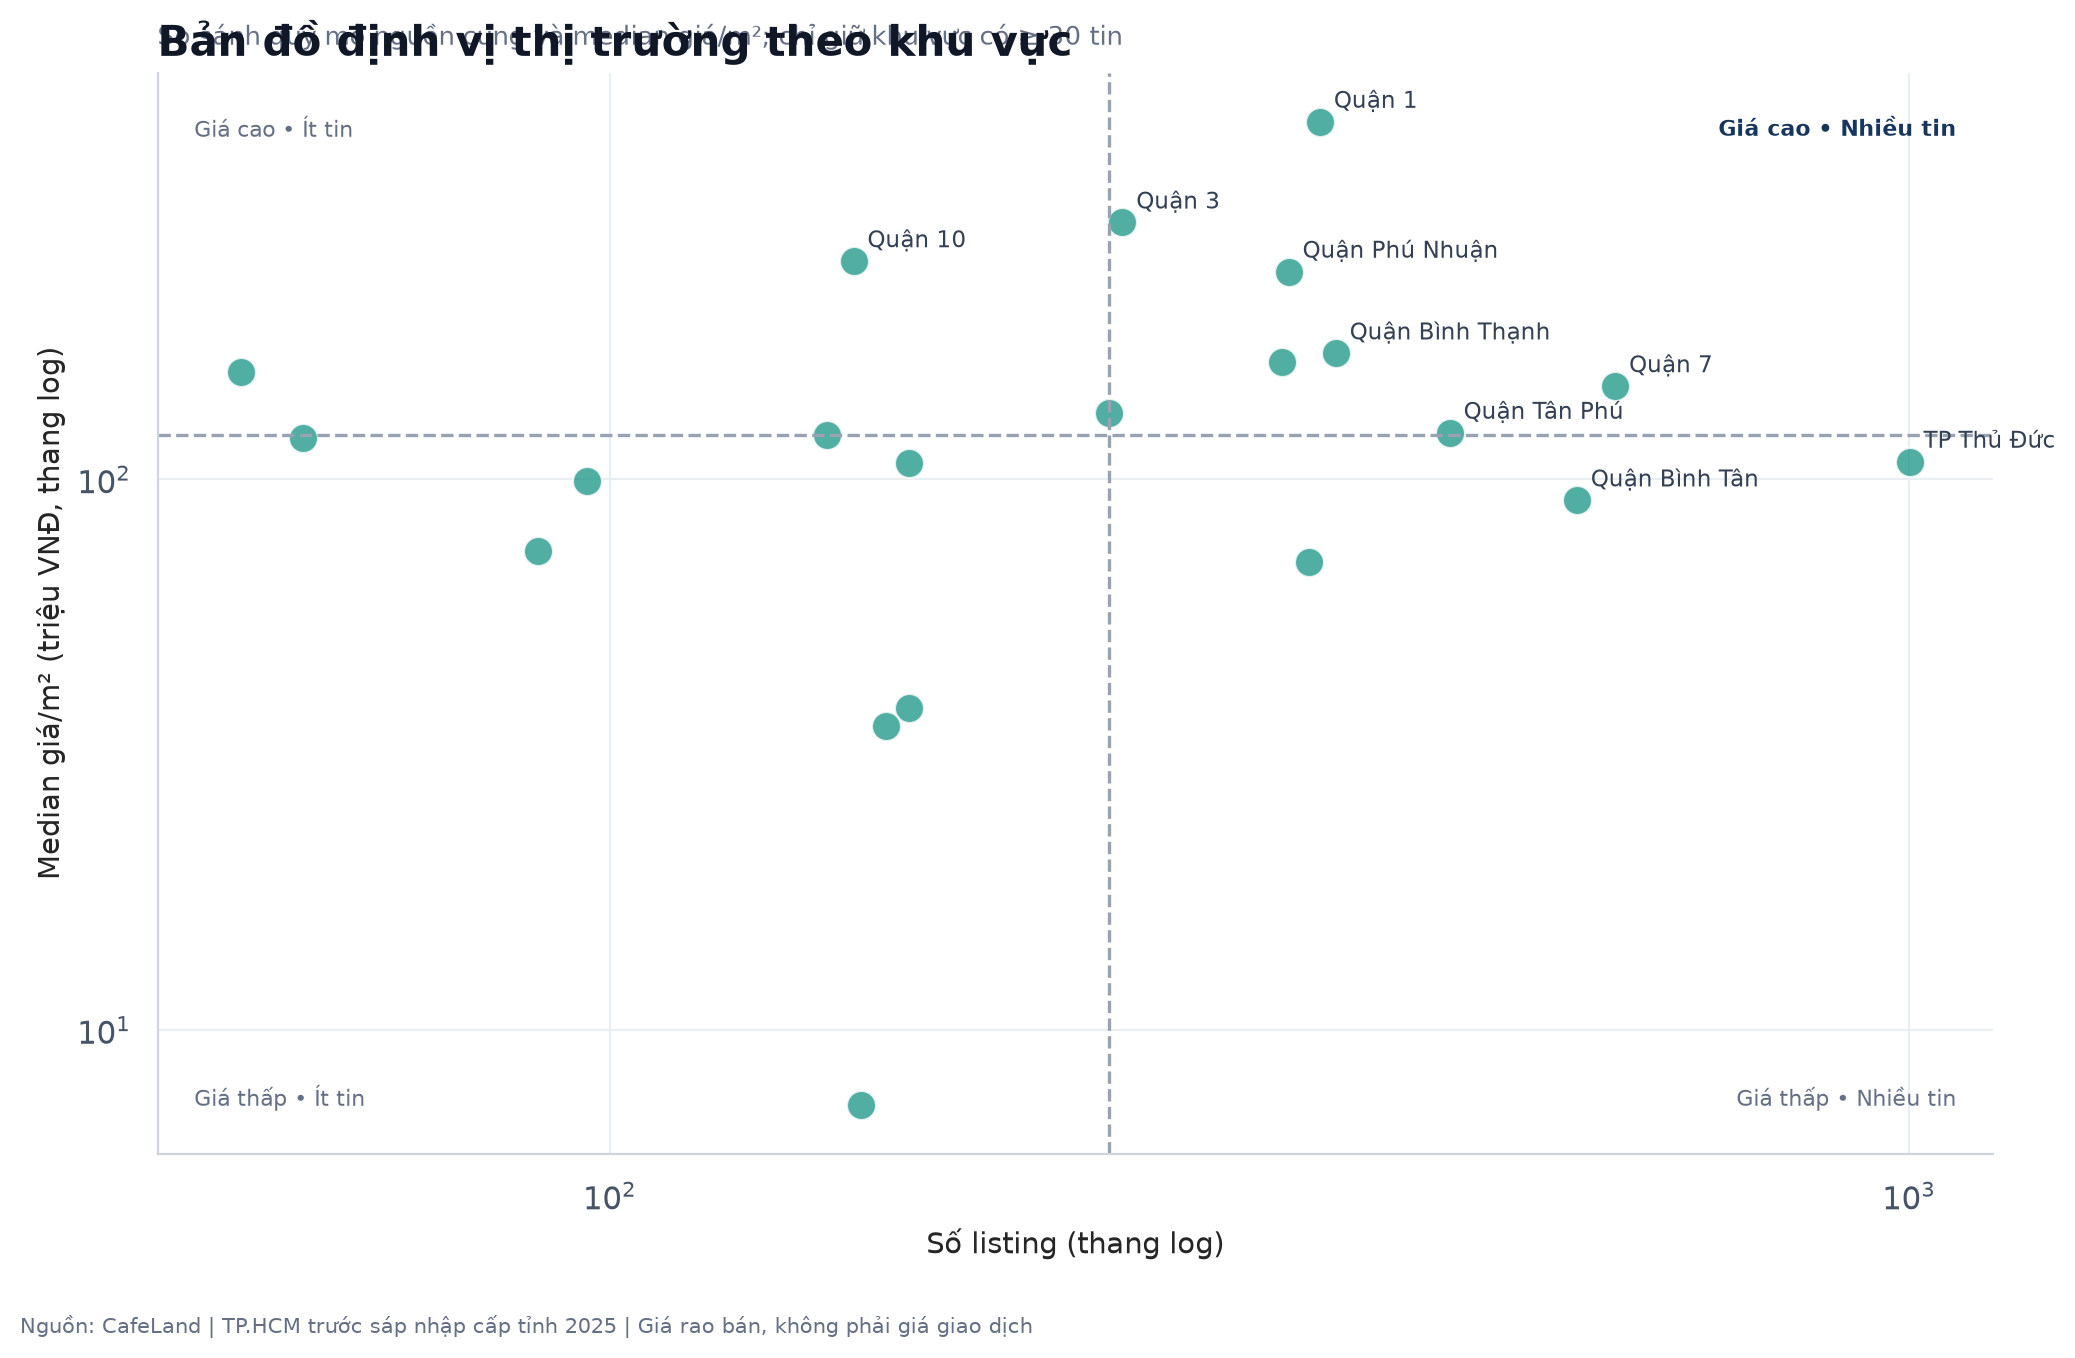

### interactive_treemap

Biểu đồ tương tác Plotly: `C:\Users\LEGION\Downloads\DAP_Final_Project_BT1_BT2\DAP_Final_Project\reports\figures\13_market_treemap.html`

### interactive_price_area

Biểu đồ tương tác Plotly: `C:\Users\LEGION\Downloads\DAP_Final_Project_BT1_BT2\DAP_Final_Project\reports\figures\14_price_area_interactive.html`

In [6]:
for name, path in result['figures'].items():
    display(Markdown(f'### {name}'))
    if str(path).lower().endswith('.png'):
        display(Image(filename=str(path)))
    else:
        display(Markdown(f'Biểu đồ tương tác Plotly: `{path}`'))

## 6. Bảy insight chính

In [7]:
for i, insight in enumerate(result['insights'], 1):
    display(Markdown(f'**{i}.** {insight}'))

**1.** Sau kiểm soát chất lượng còn 6,086 listing; loại 304 URL hồ sơ môi giới và 62 ngoại lai mạnh.

**2.** Giá rao bán lệch phải: trung vị 9.50 tỷ VNĐ, phân vị 95% 98.30 tỷ. Phân tích log giúp hạn chế vài listing giá rất cao lấn át phần lớn thị trường.

**3.** Diện tích cũng có đuôi dài: trung vị 83.0 m², phân vị 95% 542.2 m². Vì vậy ngoại lai được đánh dấu trên log-scale thay vì cắt bằng một ngưỡng tuyệt đối.

**4.** house là loại hình lớn nhất (67.2%). Sau tái phân loại bằng title/URL, unknown còn 4.6%.

**5.** Trong khu vực có ít nhất 30 tin, Quận 1 có trung vị giá/m² cao nhất (445.6 triệu), còn Huyện Củ Chi thấp nhất (7.3 triệu). Đây là mô tả giá rao bán, không phải kết luận nhân quả.

**6.** Tương quan Spearman giữa diện tích và tổng giá là 0.53; diện tích có thông tin dự báo nhưng không đủ để giải thích toàn bộ giá.

**7.** 7.7% bản ghi cleaned mang cờ area_definition_risk. Bước modeling cần theo dõi riêng vì area_m2 ở nhà phố đôi khi có thể phản ánh diện tích sàn thay vì diện tích đất.

## 7. Feature engineering sơ bộ và định hướng BT4

- Giữ `area_m2`, `log_area_m2`, `property_type`, `legacy_area` làm feature model v1.
- `price_per_m2_*`, `price_billion`, `log_price_vnd` chỉ dùng EDA vì suy ra từ target.
- Không dùng `title`, `description`, `listing_id`, `url` trong model v1.
- Theo dõi `area_definition_risk` khi đánh giá residual.
- Dự kiến so sánh mô hình tuyến tính (Linear/Ridge) với mô hình phi tuyến dạng cây.
- Khi sang BT4, mß╗ìi preprocessing c├│ tham sß╗æ hß╗ìc tß╗½ dß╗» liß╗çu phß║úi chß╗ë fit tr├¬n train; cleaned BT3 chß╗ë l├á analytical snapshot.

In [8]:
print('Static charts:', result['static_chart_count'])
print('Interactive charts:', result['interactive_chart_count'])
print('BT3 gate:', 'PASS' if result['gate_passed'] else 'FAIL')
print('Report:', result['report_path'])

Static charts: 13
Interactive charts: 2
BT3 gate: PASS
Report: C:\Users\LEGION\Downloads\DAP_Final_Project_BT1_BT2\DAP_Final_Project\docs\BT3_submission.md


## 8. Peer review

Biên bản peer review được lưu ở `docs/peer_review.md`. Phản hồi chéo nhóm phải là phản hồi thật; repository không tự tạo nội dung phản hồi để đạt rubric.